# Distributed coding of choice, action and engagement: full analysis

This notebook reproduces the analyses of the paper (Nature 576:266, 2019) from the data in `data/allData/`, section by section.
Every result comes from the same code as `run_all.py` (the `steinmetz` package and the `figures` package), so the notebook cannot drift from the pipeline.

**How to use it**

| Setting | What it does | Time |
|---|---|---|
| `RUN_MODE = "session"` | One session, `Moniz_2017-05-16`, which has VISp, LGd and LP | About 2 minutes |
| `RUN_MODE = "full"` | All 39 sessions, sharing `results/` with `run_all.py` | About 1 hour on one worker |

Run the cells from the top. Each stage skips work already saved, so it is safe to run again after an interruption.

**One session cannot reproduce the paper.** In `"session"` mode, region statistics rest on a few neurons from one mouse, and the rule that a region needs two mice is relaxed. Use that mode to read and check the method, and `"full"` mode for results.
Differences from the paper are collected in section 13.

**Contents**

1. Setup
2. The dataset
3. Behavior (Fig 1c-d, Ext 1)
4. Selecting trials
5. Selecting neurons and regions
6. Firing rates
7. Kernel regression (Fig 3, Ext 5, Ext 6a)
8. Single neurons and propagation (Fig 1, Fig 2, Ext 2-4)
9. Choice signals: decoding and jPECC (Fig 4, Ext 8)
10. Choice and detect probability (Ext 7)
11. Task engagement (Fig 5, Ext 6b, Ext 9)
12. Assignment figures: VISp, LGd, LP
13. Comparison with the paper
14. Runtime and memory

## 1. Setup

In [ ]:
RUN_MODE = "full"           # "session" or "full"
DEMO_SESSION = "Moniz_2017-05-16"
WORKERS = None                 # None sets it from free RAM in full mode

In [2]:
import io
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "1")  # one numerical thread per worker

ANALYSIS = Path.cwd() if (Path.cwd() / "steinmetz").exists() else Path.cwd() / "analysis"
sys.path.insert(0, str(ANALYSIS))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage, Markdown, display
from PIL import Image

from figures.build import make_all
from run_all import expected_peak
from steinmetz import behavior, cccp, decoding, engagement, jpecc, pipeline, rates, regression as rr, report, store, trials
from steinmetz import config as C
from steinmetz.config import Config
from steinmetz.data import Session, list_sessions, subject_of
from steinmetz.regions import neuron_regions, to_paper_region
from steinmetz.results import PSTH_T, Results
from steinmetz.style import CONTRA, IPSI, REGION_COLORS

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 8, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 60, "display.width", 140)

In [3]:
cfg = Config()
if RUN_MODE == "session":
    cfg = replace(cfg, results=ANALYSIS / "results_notebook" / DEMO_SESSION, output=ANALYSIS / "output_notebook" / DEMO_SESSION, min_subjects=1)
    sessions = [DEMO_SESSION]
    workers = WORKERS or 1
else:
    sessions = list_sessions(cfg.data)
    workers = WORKERS or pipeline.auto_workers(expected_peak(cfg))

cfg.results.mkdir(parents=True, exist_ok=True)
runner = pipeline.Runner(cfg, workers)
STAGES = pipeline.steps(cfg, sessions, runner)


def run(*names):
    # Run pipeline stages by name. Finished work is skipped.
    for n in names:
        runner.stage(n, STAGES[n])


def show(name, folder="figures", width=1150):
    # Show a saved figure, reduced so the notebook file stays small.
    im = Image.open(cfg.output / folder / f"{name}.png").convert("RGB")
    s = min(1, width / im.width)
    buf = io.BytesIO()
    im.resize((int(im.width * s), int(im.height * s)), Image.LANCZOS).save(buf, "PNG", optimize=True)
    display(IPImage(data=buf.getvalue()))


def figure(*names):
    # Build figures from saved results, then show them.
    failed = make_all(cfg, set(names))
    if failed:
        raise RuntimeError(failed)
    for n in names:
        show(n)


print(f"mode: {RUN_MODE}, sessions: {len(sessions)}, workers: {workers}")
print(f"results: {cfg.results}")
print(f"figures: {cfg.output}")

mode: session, sessions: 1, workers: 1
results: E:\Research\IPM\Mehdi-Sanayei\Task\analysis\results_notebook\Moniz_2017-05-16
figures: E:\Research\IPM\Mehdi-Sanayei\Task\analysis\output_notebook\Moniz_2017-05-16


## 2. The dataset

The dataset holds 39 sessions from 10 mice, recorded with Neuropixels probes in the left hemisphere. Each session is a folder of arrays: spikes with their cluster, trial events, wheel, video-derived signals, and each channel's brain location.

Because all recordings are in the left hemisphere, **contra means the right stimulus and the Right choice** throughout.

In [4]:
rows = []
for s in list_sessions(cfg.data):
    ses = Session(cfg.data, s)
    inc, ann = ses.a("trials.included"), ses.a("clusters._phy_annotation")
    rows.append(dict(session=s, mouse=subject_of(s), trials=len(inc), included=int(inc.sum()), clusters=len(ann), good_units=int((ann >= 2).sum()),
                     probes=int(ses.a("clusters.probes").max()) + 1, spikes_M=round((ses.path / "spikes.times.npy").stat().st_size / 8e6, 1)))
session_table = pd.DataFrame(rows)
print(f"{len(session_table)} sessions, {session_table.mouse.nunique()} mice, {session_table.included.sum()} included trials (paper: {C.INCLUDED_TRIALS})")
session_table

39 sessions, 10 mice, 9538 included trials (paper: 9538)


,session,mouse,trials,included,clusters,good_units,probes,spikes_M
0,Cori_2016-12-14,Cori,214,201,1085,734,2,10.0
1,Cori_2016-12-17,Cori,251,229,1146,1070,2,10.4
2,Cori_2016-12-18,Cori,228,216,1089,619,2,17.9
3,Forssmann_2017-11-01,Forssmann,249,241,2073,1769,3,13.3
4,Forssmann_2017-11-02,Forssmann,254,246,1569,1077,3,10.4
5,Forssmann_2017-11-04,Forssmann,290,288,1435,1169,3,8.2
6,Forssmann_2017-11-05,Forssmann,252,244,1029,584,2,7.9
7,Hench_2017-06-15,Hench,250,223,1707,1157,3,19.4
8,Hench_2017-06-16,Hench,372,350,1364,788,3,15.0
9,Hench_2017-06-17,Hench,447,430,1591,1172,3,17.8


In [5]:
EXAMPLE = "Moniz_2017-05-16"
ses = Session(cfg.data, EXAMPLE)
print(len(list(ses.path.iterdir())), "files, for example:")
print(sorted(p.name for p in ses.path.iterdir())[:14])
tr = trials.build_trials(ses)
pd.DataFrame({k: tr[k] for k in ("stim", "cue", "fb_time", "cl", "cr", "choice", "fb", "included")}).head(8).round(3)

55 files, for example:
['Moniz_2017-05-16_A_g0_t0.imec.lf.timestamps.npy', 'Moniz_2017-05-16_V1_g1_t0.imec.lf.timestamps.npy', 'channels.brainLocation.tsv', 'channels.probe.npy', 'channels.rawRow.npy', 'channels.site.npy', 'channels.sitePositions.npy', 'clusters._phy_annotation.npy', 'clusters.depths.npy', 'clusters.originalIDs.npy', 'clusters.peakChannel.npy', 'clusters.probes.npy', 'clusters.templateWaveformChans.npy', 'clusters.templateWaveforms.npy']


,stim,cue,fb_time,cl,cr,choice,fb,included
0,66.828,67.525,67.988,0.00,0.50,-1.0,1.0,True
1,70.328,71.244,71.681,0.00,0.50,-1.0,1.0,True
2,75.377,76.366,77.899,0.00,0.00,0.0,1.0,True
3,79.278,79.925,80.197,1.00,0.00,1.0,1.0,True
4,82.060,82.815,83.213,1.00,0.25,1.0,1.0,True
5,85.043,85.810,87.315,0.25,0.25,0.0,-1.0,True
6,89.760,90.936,91.830,0.50,0.00,1.0,1.0,True
7,93.910,94.846,94.976,0.50,0.00,-1.0,-1.0,True


### Sign conventions

These decide every contra/ipsi panel, so they are checked directly against the rewards, not assumed:

- `response_choice`: **+1 is a Left choice**, rewarded when the left stimulus has higher contrast; **-1 is a Right choice**; 0 is NoGo.
- `wheelMoves.type`: **1 is a left turn, 2 a right turn**, 0 and 3 are other movements.
- `clusters.peakChannel` counts from 1, so it is reduced by one before indexing channels.

In [6]:
rewarded = tr["fb"] == 1
assert (tr["choice"][rewarded & (tr["cl"] > tr["cr"])] == 1).all()
assert (tr["choice"][rewarded & (tr["cr"] > tr["cl"])] == -1).all()
print("Left-choice sign confirmed on", int((rewarded & (tr['cl'] > tr['cr'])).sum()), "rewarded trials")
print("Right-choice sign confirmed on", int((rewarded & (tr['cr'] > tr['cl'])).sum()), "rewarded trials")
print(f"wheel type 1 agrees with a Left choice on {100 * (tr['choice'][tr['has_left']] == 1).mean():.1f}% of trials")
print(f"wheel type 2 agrees with a Right choice on {100 * (tr['choice'][tr['has_right']] == -1).mean():.1f}% of trials")
print("contrast pairs in this session:")
pd.crosstab(tr["cl"], tr["cr"], rownames=["left contrast"], colnames=["right contrast"])

Left-choice sign confirmed on 35 rewarded trials
Right-choice sign confirmed on 50 rewarded trials
wheel type 1 agrees with a Left choice on 91.7% of trials
wheel type 2 agrees with a Right choice on 85.7% of trials
contrast pairs in this session:


right contrast,0.00,0.25,0.50,1.00
left contrast,,,,
0.00,47,11,12,12
0.25,8,20,9,12
0.50,13,16,11,8
1.00,18,19,6,13


## 3. Behavior

Mice turned a wheel to bring the higher-contrast stimulus to the center, or held still if there was no stimulus. Figure 1c shows the mean choice probability per contrast pair, and Fig 1d shows reaction time against chosen contrast.

Each subject's choices are fit with the multinomial model of the Extended Data Fig 1 legend:

$$\ln\frac{p_L}{p_{NoGo}} = b_L + s_L c_L^{\,n}, \qquad \ln\frac{p_R}{p_{NoGo}} = b_R + s_R c_R^{\,n}$$

Figure 1d splits trials into **one stimulus** and **two stimuli**. The paper's ANOVA factors are not stated, so chosen contrast, stimulus count and subject are used.

In [7]:
run("base", "regions", "wheel", "behavior")
b = store.load(cfg.results / "behavior.npz")
pd.DataFrame({str(s): b[f"params|{s}"] for s in b["subjects"]}, index=["bL", "sL", "n", "bR", "sR"]).round(2)

base: 2.85 s, peak 0.936 GB
regions: 0.01 s, peak 0.0 GB
wheel: 0.19 s, peak 0.0 GB
behavior: 0.04 s, peak 0.0 GB


,Moniz
bL,-2.18
sL,3.41
n,0.67
bR,-1.76
sR,4.24


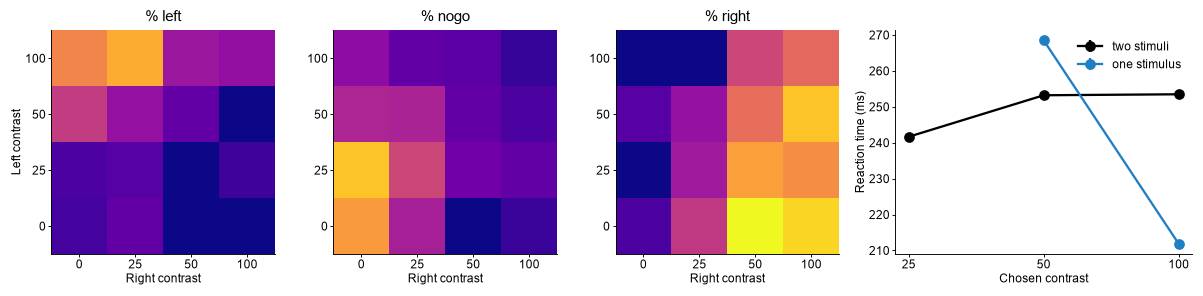

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.3]})
for ax, key in zip(axes, ("left", "nogo", "right")):
    im = ax.imshow(b[f"map_{key}"], origin="lower", cmap="plasma", vmin=0, vmax=100)
    ax.set_title(f"% {key}"), ax.set_xticks(range(4), ["0", "25", "50", "100"]), ax.set_yticks(range(4), ["0", "25", "50", "100"])
    ax.set_xlabel("Right contrast")
axes[0].set_ylabel("Left contrast")
pos = {0.25: 0, 0.5: 1, 1.0: 2}
for two, color, name in ((1.0, "k", "two stimuli"), (0.0, "#1f7fc4", "one stimulus")):
    m = b["rt_two"] == two
    axes[3].errorbar([pos[v] for v in b["rt_chosen"][m]], b["rt_mean"][m], b["rt_sem"][m], color=color, marker="o", label=name)
axes[3].set_xticks([0, 1, 2], ["25", "50", "100"]), axes[3].set_xlabel("Chosen contrast"), axes[3].set_ylabel("Reaction time (ms)"), axes[3].legend(frameon=False)
plt.tight_layout()

Wheel movement detection is checked by decoding the direction of each turn from its instantaneous velocity (position change over 10 ms). It should sit at chance before the detected onset and rise after it (Ext 1q).

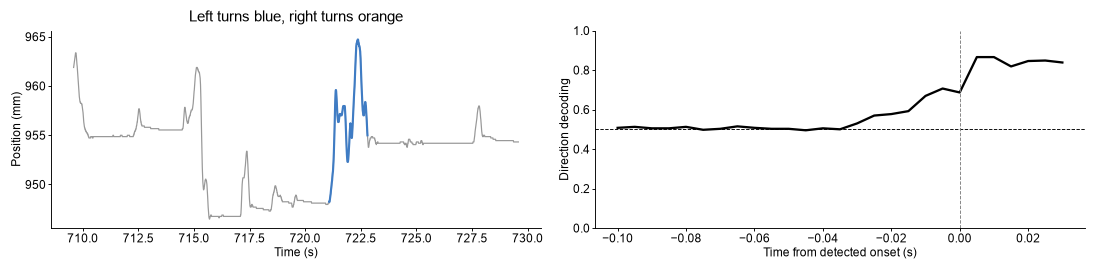

In [9]:
t, mm = behavior.wheel_mm(ses)
on, off, kind = ses.moves()
start = on[len(on) // 2]
m = (t >= start) & (t <= start + 20)
fig, axes = plt.subplots(1, 2, figsize=(10, 2.5))
axes[0].plot(t[m][::20], mm[m][::20], color="#999999", lw=0.8)
for a, z, k in zip(on, off, kind):
    if start <= a <= start + 20 and k in (1, 2):
        w = (t >= a) & (t <= z)
        axes[0].plot(t[w][::20], mm[w][::20], color={1: IPSI, 2: CONTRA}[k], lw=1.4)
axes[0].set_xlabel("Time (s)"), axes[0].set_ylabel("Position (mm)"), axes[0].set_title("Left turns blue, right turns orange")
acc = np.array([store.load(cfg.results / "wheel" / f"{s}.npz")["acc"] for s in sessions])
off_t = np.arange(-0.1, 0.0301, 0.005)
axes[1].plot(off_t, acc.mean(0), "k"), axes[1].axhline(0.5, ls="--", color="k", lw=0.6), axes[1].axvline(0, ls="--", color="gray", lw=0.6)
axes[1].set_xlabel("Time from detected onset (s)"), axes[1].set_ylabel("Direction decoding"), axes[1].set_ylim(0, 1)
plt.tight_layout()

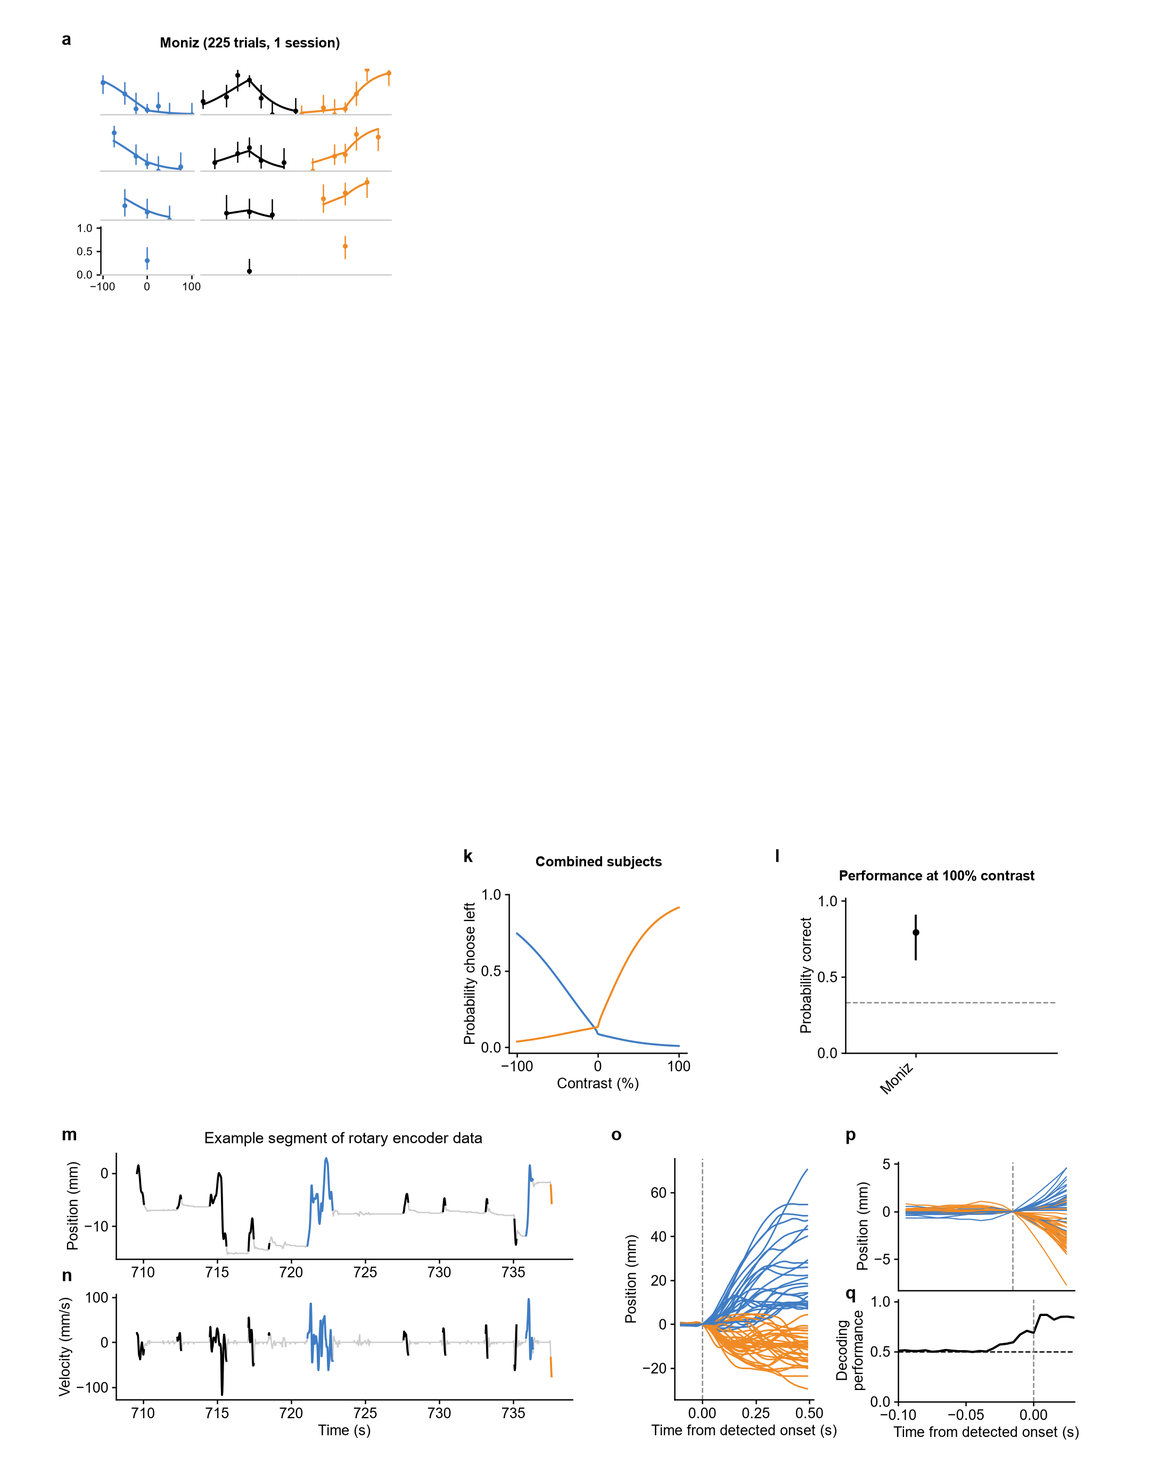

In [10]:
figure("ext1")

## 4. Selecting trials

The analyses need clean trial groups. **Left** and **Right** trials have a first movement of the right kind between 125 and 400 ms after the stimulus. Two definitions of a no-movement trial are in use, and they differ for a reason:

| Set | Definition | Used for |
|---|---|---|
| Authors' `hasNone` | First movement came before feedback but outside the window | Kernel regression, decoding |
| Methods' NoGo | No detected movement at all from -50 to 400 ms | Fig 2, Fig 5, Ext 6b, Ext 9, ccCP |

The authors' list leaves out fully still trials, which looks unintended but defines their regression, so the regression keeps it. The population analyses follow the Methods text.

In [11]:
pd.Series({k: int(tr[k].sum()) for k in ("included", "has_left", "has_right", "has_none", "still", "kernel_trial", "go", "nogo", "miss", "correct_contra", "correct_ipsi", "miss_contra", "miss_ipsi")}, name="trials").to_frame()

,trials
included,225
has_left,12
has_right,35
has_none,128
still,158
kernel_trial,173
go,47
nogo,149
miss,111
correct_contra,26


In [12]:
lists = C.AUTHORS_REPO / "behavior" / "inclusionData" / "trials"
same = {f: (tr[k] == np.load(lists / f"{EXAMPLE}_{f}.npy").ravel().astype(bool)).all() for k, f in (("has_left", "hasLeft"), ("has_right", "hasRight"), ("has_none", "hasNone"))}
print("matches the authors' published lists:", same)

matches the authors' published lists: {'hasLeft': np.True_, 'hasRight': np.True_, 'hasNone': np.True_}


### Contrast matching

Some comparisons must not differ in visual drive. For each contra contrast (low, medium, high), trials are counted in the three groups and the smallest count is drawn at random from each. A session with under 10 matched trials is dropped.

This applies to Fig 2d, f, h, Fig 5a-b and Ext 6b. The Go group here is **correct contra choice** trials: that gives the paper's 34 sessions, while any Left or Right trial would keep 36.

### Session rules

Choice probability cannot use a stimulus condition where the mouse made only one choice, so a session needs at least 10 includable trials. Detect probability applies the same threshold to its own Go and NoGo trials.

In [13]:
rows = []
for s in list_sessions(cfg.data):
    q = trials.build_trials(Session(cfg.data, s))
    cond = trials.condition_ids(q)
    left, right = q["included"] & q["has_left"], q["included"] & q["has_right"]
    m = trials.matched_sets(q, store.session_rng(cfg.seed, s, 10))
    rows.append(dict(session=s, matched=len(m["go"]) if m else 0, cp_trials=int(trials.includable(left, right, cond).sum()), dp_trials=int(trials.includable(q["go"], q["nogo"], cond).sum())))
rules = pd.DataFrame(rows)
print(f"contrast matching keeps {(rules.matched >= 10).sum()} of 39 (paper: 34)")
print(f"CP keeps {(rules.cp_trials >= 10).sum()} of 39 (paper: 33)")
print(f"DP keeps {(rules.dp_trials >= 10).sum()} of 39 (paper: not stated)")
rules[(rules.matched < 10) | (rules.cp_trials < 10)]

contrast matching keeps 34 of 39 (paper: 34)
CP keeps 33 of 39 (paper: 33)
DP keeps 39 of 39 (paper: not stated)


,session,matched,cp_trials,dp_trials
0,Cori_2016-12-14,26,3,155
11,Lederberg_2017-12-05,0,75,75
12,Lederberg_2017-12-06,0,41,144
13,Lederberg_2017-12-07,0,44,118
20,Moniz_2017-05-18,10,5,58
22,Muller_2017-01-08,11,0,121
23,Muller_2017-01-09,13,6,153
27,Radnitz_2017-01-11,15,0,112
36,Tatum_2017-12-08,0,13,94
37,Tatum_2017-12-09,0,8,118


## 5. Selecting neurons and regions

Spikes are already sorted in the dataset. A unit counts as a neuron if it is labelled good and fires at 0.1 sp/s or more from stimulus onset to 400 ms. Its region is the Allen label at its peak channel.

The dataset has 73 raw labels and the paper uses 42 regions. Each raw label is mapped to its nearest ancestor among the 42 in the Allen hierarchy, by rule, for example `SCig` to `SCm`. Non-specific labels such as `root` or `TH` are not localizable.

A region is kept in a session with at least 13 neurons there, and overall only if at least 2 mice have that many (relaxed to 1 in session mode).

| Set | Definition | Used for |
|---|---|---|
| All | Base neurons in a kept region | Fig 5, Ext 6b, Ext 7, Ext 9, jPECC |
| Responsive | Any of six task tests at p < 0.0083 | Table 1 counts |
| Highly activated | Sliding rank-sum, p < 0.0001 in 3 bins | Fig 2d-h heatmaps, Ext 4b-e |
| Regression | Authors' published list | Fig 3, Fig 4a-c, f-g, Ext 5, Ext 6a |

In [14]:
raw, region = neuron_regions(ses)
ann = ses.a("clusters._phy_annotation")
good = ann >= 2
pd.DataFrame({"raw": raw[good], "paper region": np.where(region[good] == "", "(not localizable)", region[good])}).value_counts().rename("units").head(16).to_frame()

,,units
raw,paper region,
TH,(not localizable),191
MG,MG,158
LGd,LGd,147
VISp,VISp,122
VISa,VISa,78
SUB,SUB,51
DG,DG,45
SPF,(not localizable),38
CA1,CA1,37


{'all': 596, 'responsive': 290, 'regression': 342}


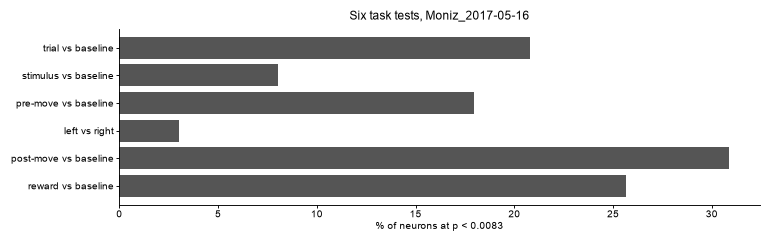

In [15]:
s0 = sessions[0]
base = store.load(cfg.results / "base" / f"{s0}.npz")
sets = pipeline.neuron_sets(cfg, s0, base)
print({k: int(v.sum()) for k, v in sets.items()})
tests = ["trial vs baseline", "stimulus vs baseline", "pre-move vs baseline", "left vs right", "post-move vs baseline", "reward vs baseline"]
p = base["n_p"][sets["all"]]
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.barh(tests[::-1], 100 * (p < C.ALPHA_RESPONSIVE).mean(0)[::-1], color="#555555")
ax.set_xlabel("% of neurons at p < 0.0083"), ax.set_title(f"Six task tests, {s0}")
plt.tight_layout()

### Region counts against Extended Data Table 1

The released labels do not reproduce the paper's table region by region, although the total is close. Reading labels again from the atlas at each channel's position was tried once and was far worse, so the released labels stay. In particular LGd (-2.8%) and LP (-7.1%) keep slightly fewer neurons than the paper. `label_check.py` repeats this test.

## 6. Firing rates

Spikes are binned at 5 ms and smoothed with a **causal** half-Gaussian, so activity never appears before the spike that caused it. For display, rates get 20 ms smoothing, trial averaging, then 30 ms smoothing. Normalized rates subtract the baseline (-20 to 0 ms) and divide by baseline + 0.5 sp/s:

$$r_{norm}(t) = \frac{r(t) - r_{base}}{r_{base} + 0.5}$$

For the side bars of Fig 2d-h and Fig 5b, the mean rate from 0 to 250 ms is z-scored against trial-by-trial baseline. Methods says two-sided (|z| > 4) while the captions read as one-sided. The figures follow Methods, and section 13 gives both counts.

psth: 3.5 s, peak 0.727 GB


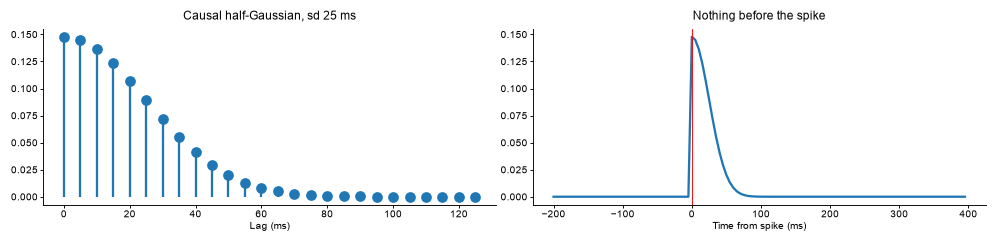

In [16]:
run("psth")
g = rates.half_gaussian(0.025)
x = np.zeros(120); x[40] = 1
fig, axes = plt.subplots(1, 2, figsize=(9, 2.2))
axes[0].stem(np.arange(len(g)) * C.DT * 1000, g, basefmt=" "), axes[0].set_xlabel("Lag (ms)"), axes[0].set_title("Causal half-Gaussian, sd 25 ms")
axes[1].plot((np.arange(120) - 40) * C.DT * 1000, rates.smooth(x, 0.025)), axes[1].axvline(0, color="r", lw=0.6), axes[1].set_xlabel("Time from spike (ms)"), axes[1].set_title("Nothing before the spike")
plt.tight_layout()

In [17]:
res = Results(cfg)
n = res.neurons()
table = n.groupby("region").agg(neurons=("cluster", "size"), responsive=("responsive", "sum"))
table["table_1_total"] = [C.TABLE1_TOTAL.get(r, 0) for r in table.index]
print(f"{len(n)} neurons in kept regions")
table.sort_values("neurons", ascending=False)

596 neurons in kept regions


,neurons,responsive,table_1_total
region,,,
MG,149,93,276
LGd,135,41,811
VISp,96,50,923
VISa,66,34,285
SUB,50,32,669
DG,43,18,711
CA1,30,10,1129
LP,27,12,732


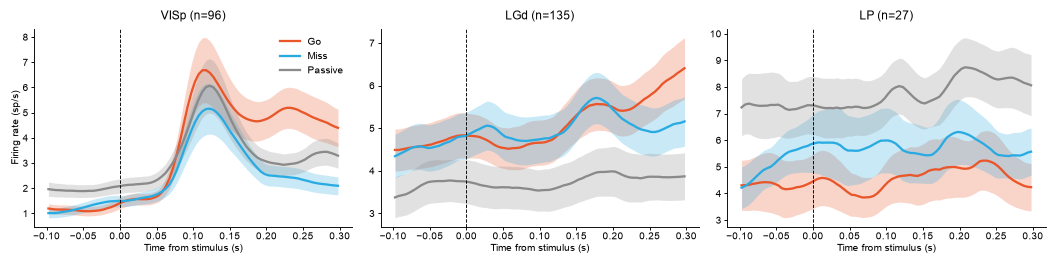

In [18]:
regions_here = [r for r in C.ASSIGNMENT_REGIONS if (n.region == r).any()]
fig, axes = plt.subplots(1, max(len(regions_here), 1), figsize=(3.2 * max(len(regions_here), 1), 2.4), squeeze=False)
for ax, r in zip(axes[0], regions_here):
    for key, color, label in (("rate_contra_correct", "#e8562a", "Go"), ("rate_contra_miss", "#29abe2", "Miss"), ("rate_contra_passive", "#8a8a8a", "Passive")):
        got = res.region_rate(key, r)
        if got:
            ax.plot(PSTH_T, got[0], color=color, label=label)
            ax.fill_between(PSTH_T, got[0] - got[1], got[0] + got[1], color=color, alpha=0.25, lw=0)
    ax.axvline(0, color="k", ls="--", lw=0.6), ax.set_title(f"{r} (n={int((n.region == r).sum())})"), ax.set_xlabel("Time from stimulus (s)")
axes[0][0].set_ylabel("Firing rate (sp/s)"), axes[0][0].legend(frameon=False)
plt.tight_layout()

## 7. Kernel regression

Each neuron's rate is a sum of temporal kernels locked to stimuli and movements:

$$\hat f_n(t) = \sum_c \sum_{t_s \in S_c} K_{c,n}(t - t_s) + \sum_{t_m \in M} \Big( K_{m,n}(t - t_m) + D_m\, K_{D,n}(t - t_m) \Big)$$

There are six Vision kernels (three contrasts on each side, 90 lags, -50 to 400 ms), an Action kernel and a Choice kernel (55 lags each, -250 to 25 ms), which gives 650 predictors.

**$D_m$ is +1 for Left (ipsi) and -1 for Right (contra).** So the predicted responses are Contra = Action - Choice and Ipsi = Action + Choice, and a *negative* pre-movement Choice kernel means *contra* preference.

### Predictors

Predictors follow the authors' code exactly, including a one-bin offset between a kernel's nominal time and its bin. Only samples inside trial windows are used.

P: 14482 samples x 650 predictors, 0.24% non-zero, 173 trials


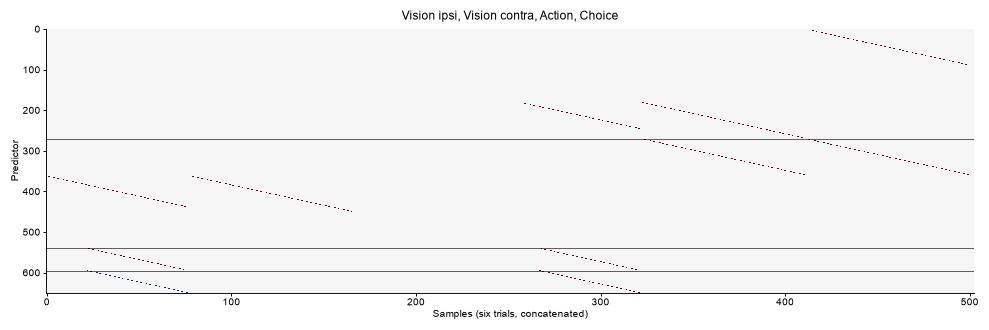

In [19]:
P, rows_, trnum, eval_full, eval_nested = rr.build_design(tr)
print(f"P: {P.shape[0]} samples x {P.shape[1]} predictors, {100 * P.nnz / np.prod(P.shape):.2f}% non-zero, {trnum.max() + 1} trials")
m = trnum < 6
fig, ax = plt.subplots(figsize=(9, 3))
ax.imshow(P[m].toarray().T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
for y in (270, 540, 595):
    ax.axhline(y, color="k", lw=0.4)
ax.set_xlabel("Samples (six trials, concatenated)"), ax.set_ylabel("Predictor"), ax.set_title("Vision ipsi, Vision contra, Action, Choice")
plt.tight_layout()

### The solver must copy glmnet's scaling

The paper fits an elastic net at $\alpha = 0.5$, $\lambda = 0.5$. In the authors' code this is plain `glmnet` at a fixed lambda (`useCVG = false`), and `GLMnet.f` scales both sides. With $x_s$ and $y_s$ the 1/T standard deviations of each column and of the neuron's rate, it minimizes

$$\frac{1}{2T}\left\| \frac{y}{y_s} - \frac{X}{x_s} b \right\|^2 + \lambda_s \left[ \frac{1-\alpha}{2}\|b\|^2 + \alpha \|b\|_1 \right], \qquad \lambda_s = \frac{0.5}{y_s}, \qquad \beta = \frac{y_s\, b}{x_s}$$

So the penalty differs per neuron. Standardizing $y$ and leaving $\lambda$ at 0.5 gives a very different fit, as this check shows. `fit_enet` solves all of a session's neurons at once by accelerated proximal gradient, because they share one Gram matrix.

In [20]:
from sklearn.linear_model import ElasticNet

rng = np.random.default_rng(1)
X = rng.normal(size=(5000, 50)) * rng.uniform(0.5, 3, 50)
y = X[:, :5].sum(1) * 2 + rng.normal(size=5000) * 12
xs, ys = X.std(0), y.std()
ref = ys * ElasticNet(alpha=0.5 / ys, l1_ratio=0.5, tol=1e-9, max_iter=100000).fit(X / xs, y / ys).coef_ / xs
ours = rr.fit_enet(X, y[:, None], tol=1e-9)[:, 0]
wrong = ElasticNet(alpha=0.5, l1_ratio=0.5, tol=1e-9, max_iter=100000).fit(X / xs, y / ys).coef_
print(f"largest difference from the reference solver: {np.abs(ours - ref).max():.1e}")
print(f"non-zero weights: reference {(ref != 0).sum()}, fit_enet {(np.abs(ours) > 1e-9).sum()}, lambda left at 0.5 {(wrong != 0).sum()}")

largest difference from the reference solver: 1.3e-09
non-zero weights: reference 11, fit_enet 11, lambda left at 0.5 1


### Reduced-rank basis, streamed

With 650 weights per neuron and few trials, fits overfit. Reduced-rank regression finds shared temporal components across all neurons, $Y \approx X\,b\,a$, and each neuron is then fit on those components.

The basis pools all sessions. To avoid holding all data in memory, each session contributes $P^TP$, $\sum P$, $T$, $\sum F$ and $P^TF$. The means matter: `CanonCor2all` uses a pooled mean for the predictor covariance but a per-session mean for the cross-covariance, and bare sums give a badly wrong basis.

### Full model, nested tests, shuffle

1. **Full model:** 5-fold by trial, ranks 1-50, best cross-validated variance explained, scored only up to movement. Neurons under 2% are excluded.
2. **Nested test** for each of Contra Vision, Ipsi Vision, Action and Choice: fit all other kernels with 75 components, take residuals, then find how well the tested kernel alone predicts them, 10-fold with 18 components. A neuron is selective at over 2%.
3. **Shuffle:** Left and Right labels are permuted and the whole analysis repeated, which estimates false positives (paper: 0.33%).

regression_data: 5.0 s, peak 1.266 GB
regression: 11.45 s, peak 0.673 GB
shuffle: 5.7 s, peak 0.674 GB
compare: 8.45 s, peak 0.84 GB
342 regression neurons, 72 pass the 2% full-model cut
{'vision_contra': 28, 'vision_ipsi': 1, 'action': 7, 'choice': 0}
shuffle: 0 of 67 pass, 0.00% (paper: 0.33%)


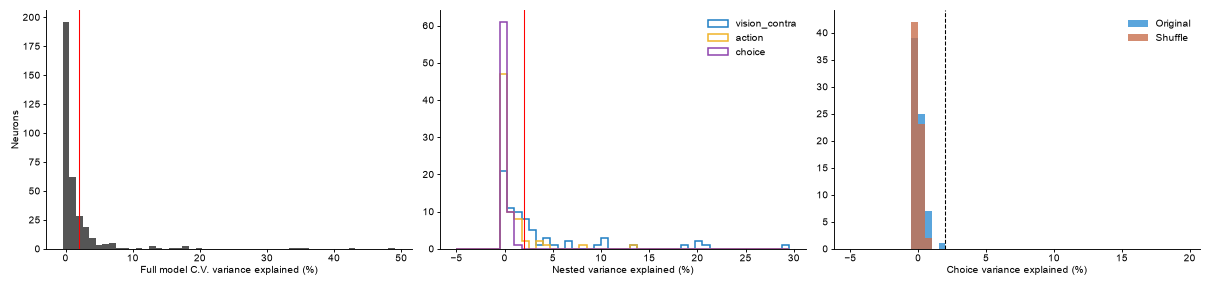

In [21]:
run("regression_data", "regression", "shuffle", "compare")
res = Results(cfg)
t = res.regression()
inc = t[t.ve >= C.VE_THRESHOLD]
sh = res.shuffle_ve()
print(f"{len(t)} regression neurons, {len(inc)} pass the 2% full-model cut")
print({k: int((inc[k] > C.VE_THRESHOLD).sum()) for k in ("vision_contra", "vision_ipsi", "action", "choice")})
print(f"shuffle: {int((sh > C.VE_THRESHOLD).sum())} of {len(sh)} pass, {100 * (sh > C.VE_THRESHOLD).mean():.2f}% (paper: 0.33%)")
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
axes[0].hist(100 * t.ve, bins=50, color="#555555"), axes[0].axvline(2, color="r", lw=0.7), axes[0].set_xlabel("Full model C.V. variance explained (%)"), axes[0].set_ylabel("Neurons")
for key, color in (("vision_contra", "#1f7fc4"), ("action", "#f0b429"), ("choice", "#8e44ad")):
    axes[1].hist(100 * inc[key], bins=np.arange(-5, 30, 0.75), histtype="step", color=color, label=key)
axes[1].axvline(2, color="r", lw=0.7), axes[1].set_xlabel("Nested variance explained (%)"), axes[1].legend(frameon=False)
bins = np.arange(-5, 20, 0.5)
axes[2].hist(100 * inc.choice, bins=bins, color="#5aa5dc", label="Original"), axes[2].hist(100 * sh, bins=bins, color="#c8704e", alpha=0.8, label="Shuffle")
axes[2].axvline(2, color="k", ls="--", lw=0.7), axes[2].set_xlabel("Choice variance explained (%)"), axes[2].legend(frameon=False)
plt.tight_layout()

### Kernels of the most choice-selective neuron

This shows the sign rule at work: where the Choice kernel is negative, the Right (contra) response is the larger one.

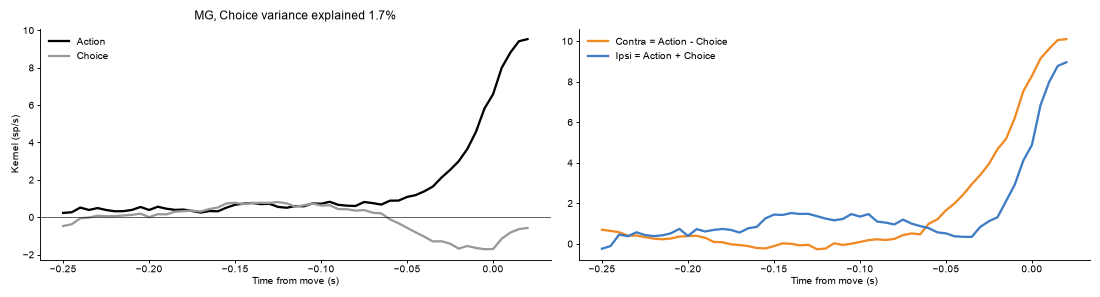

In [22]:
top = inc.sort_values("choice", ascending=False).iloc[0]
K = res.kernels(top["session"])["K"][:, int(top["index"])]
parts = rr.split_kernels(K[:, None])
lag = -0.25 + np.arange(C.LD) * C.DT
act, cho = parts["action"][:, 0], parts["choice"][:, 0]
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
axes[0].plot(lag, act, "k", label="Action"), axes[0].plot(lag, cho, color="#999999", label="Choice"), axes[0].axhline(0, color="k", lw=0.4)
axes[0].set_xlabel("Time from move (s)"), axes[0].set_ylabel("Kernel (sp/s)"), axes[0].legend(frameon=False), axes[0].set_title(f"{top['region']}, Choice variance explained {100 * top['choice']:.1f}%")
axes[1].plot(lag, act - cho, color=CONTRA, label="Contra = Action - Choice"), axes[1].plot(lag, act + cho, color=IPSI, label="Ipsi = Action + Choice")
axes[1].set_xlabel("Time from move (s)"), axes[1].legend(frameon=False)
plt.tight_layout()
print("prefers contra:", bool(top["prefers_contra"]), "| mean Choice kernel, -100 to 0 ms:", round(float(cho[(lag >= -0.1) & (lag < 0)].mean()), 2))

In [23]:
coding = (inc.assign(**{k: inc[k] > C.VE_THRESHOLD for k in ("vision_contra", "vision_ipsi", "action", "choice")})
          .groupby("region")[["vision_contra", "vision_ipsi", "action", "choice"]].sum())
coding.insert(0, "passing 2%", inc.groupby("region").size())
coding.insert(0, "regression neurons", t.groupby("region").size())
coding.sort_values("regression neurons", ascending=False)

,regression neurons,passing 2%,vision_contra,vision_ipsi,action,choice
region,,,,,,
MG,75,7,0,0,2,0
VISp,69,34,26,0,2,0
LGd,63,4,0,0,0,0
SUB,40,13,0,1,0,0
VISa,40,7,2,0,3,0
DG,21,2,0,0,0,0
CA1,18,3,0,0,0,0
LP,16,2,0,0,0,0


### Focality

How concentrated a code is across regions, from the sparseness measure of ref. 54, with $p_a$ the fraction of selective neurons in region $a$:

$$F = \frac{\sum_a p_a^2}{\left(\sum_a p_a\right)^2}$$

It is 1 when all selective neurons are in one region and $1/N$ when spread evenly. The paper reports 0.040 for action, 0.069 for contra vision and 0.079 for choice.

In [24]:
pd.DataFrame({c: dict(zip(("estimate", "ci_low", "ci_high"), report.focality_interval(t, c, cfg.seed))) for c in ("action", "vision_contra", "choice")}).T.round(3)

,estimate,ci_low,ci_high
action,0.420,0.068,0.613
vision_contra,0.793,0.574,0.991
choice,NaN,NaN,NaN


### Figures: Fig 3 (encoding), Ext 5 (method), Ext 6 (variance explained)

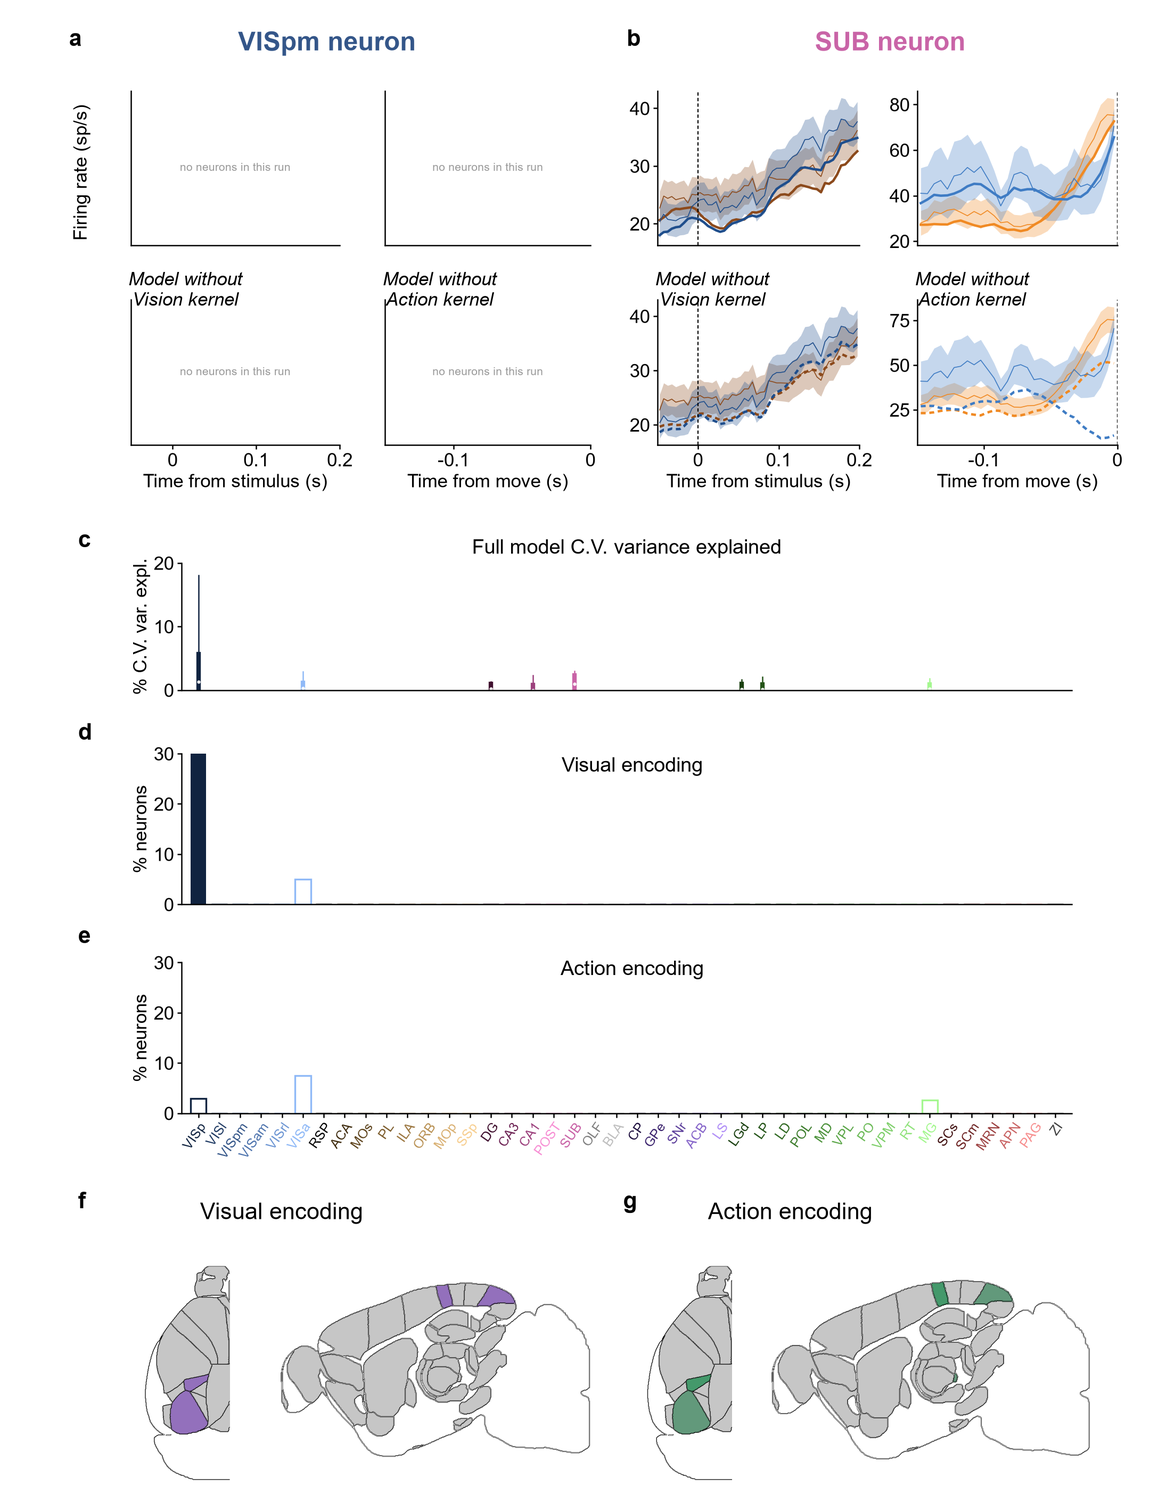

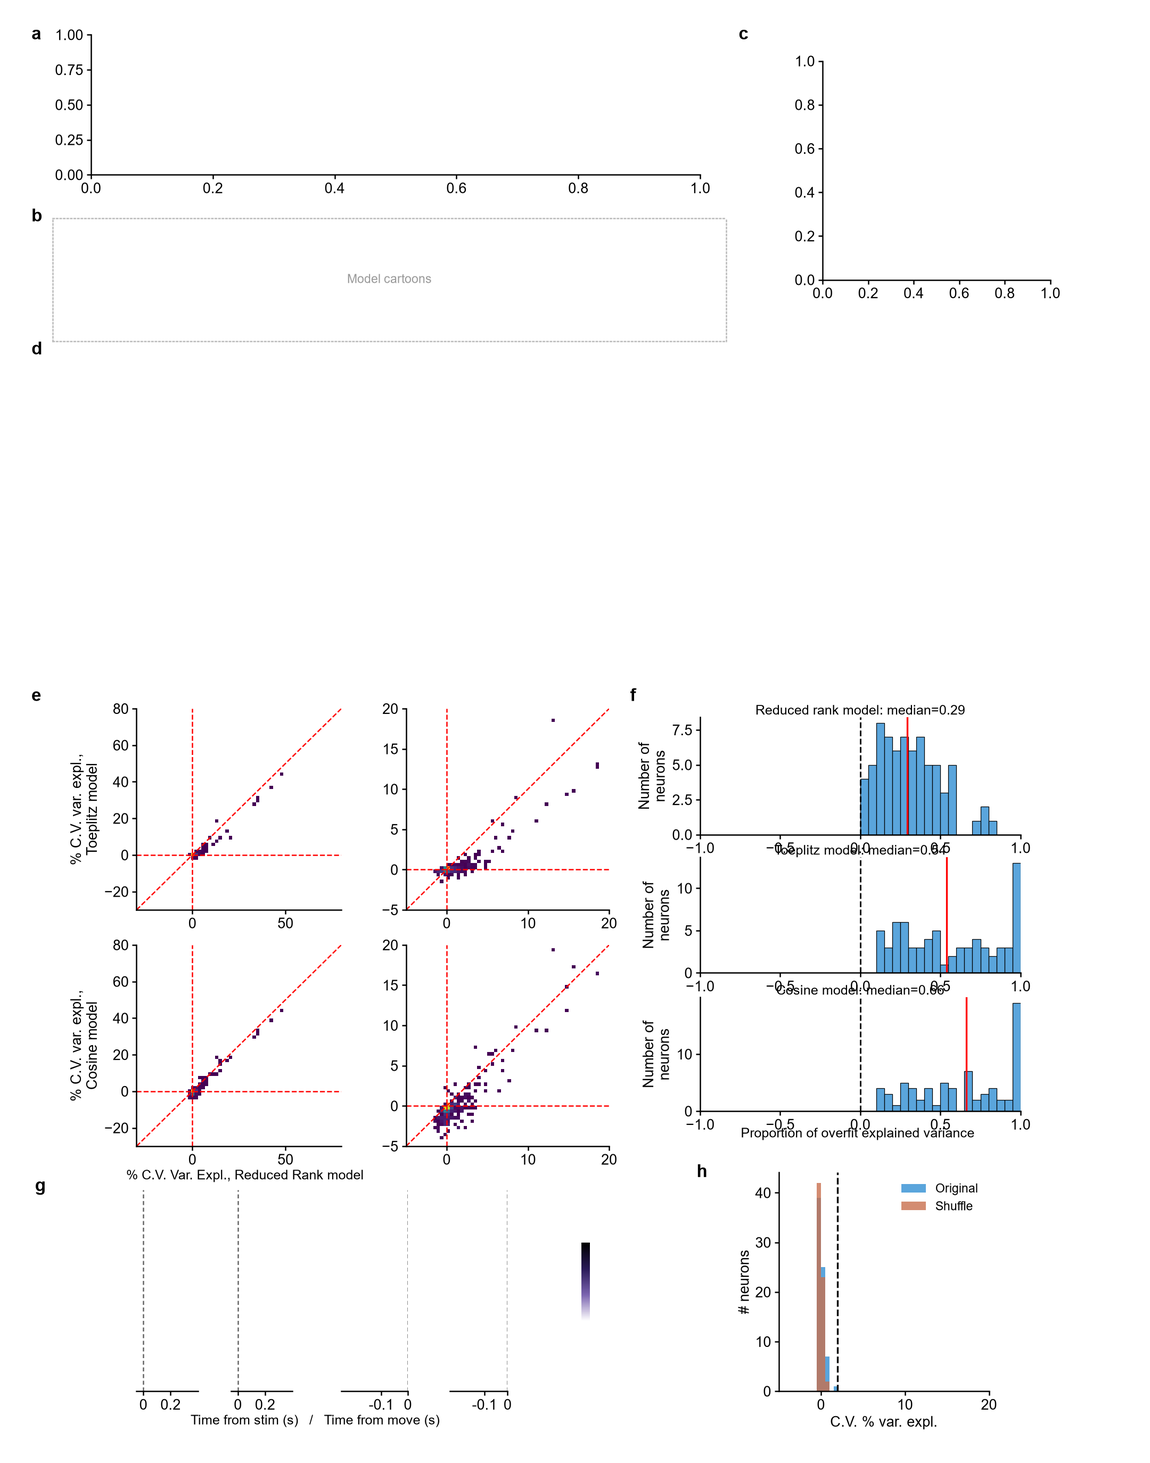

In [25]:
figure("fig3", "ext5")

## 8. Single neurons and propagation

The paper's example neurons are not identified, so each slot holds the real neuron closest to the published panel, saved in `results/example_neurons.json`. To swap one, edit that file and rebuild the figure. `example_scores.csv` lists the top five for each slot.

Fig 2d-h shows normalized rates per region across responsive neurons: activity spreads widely only when the mouse moves, and stays in a visual pathway on Miss and Passive trials. Ext 4 shows the same at the level of neurons, with latency sorting cross-validated (sorted on odd trials, plotted on even trials).

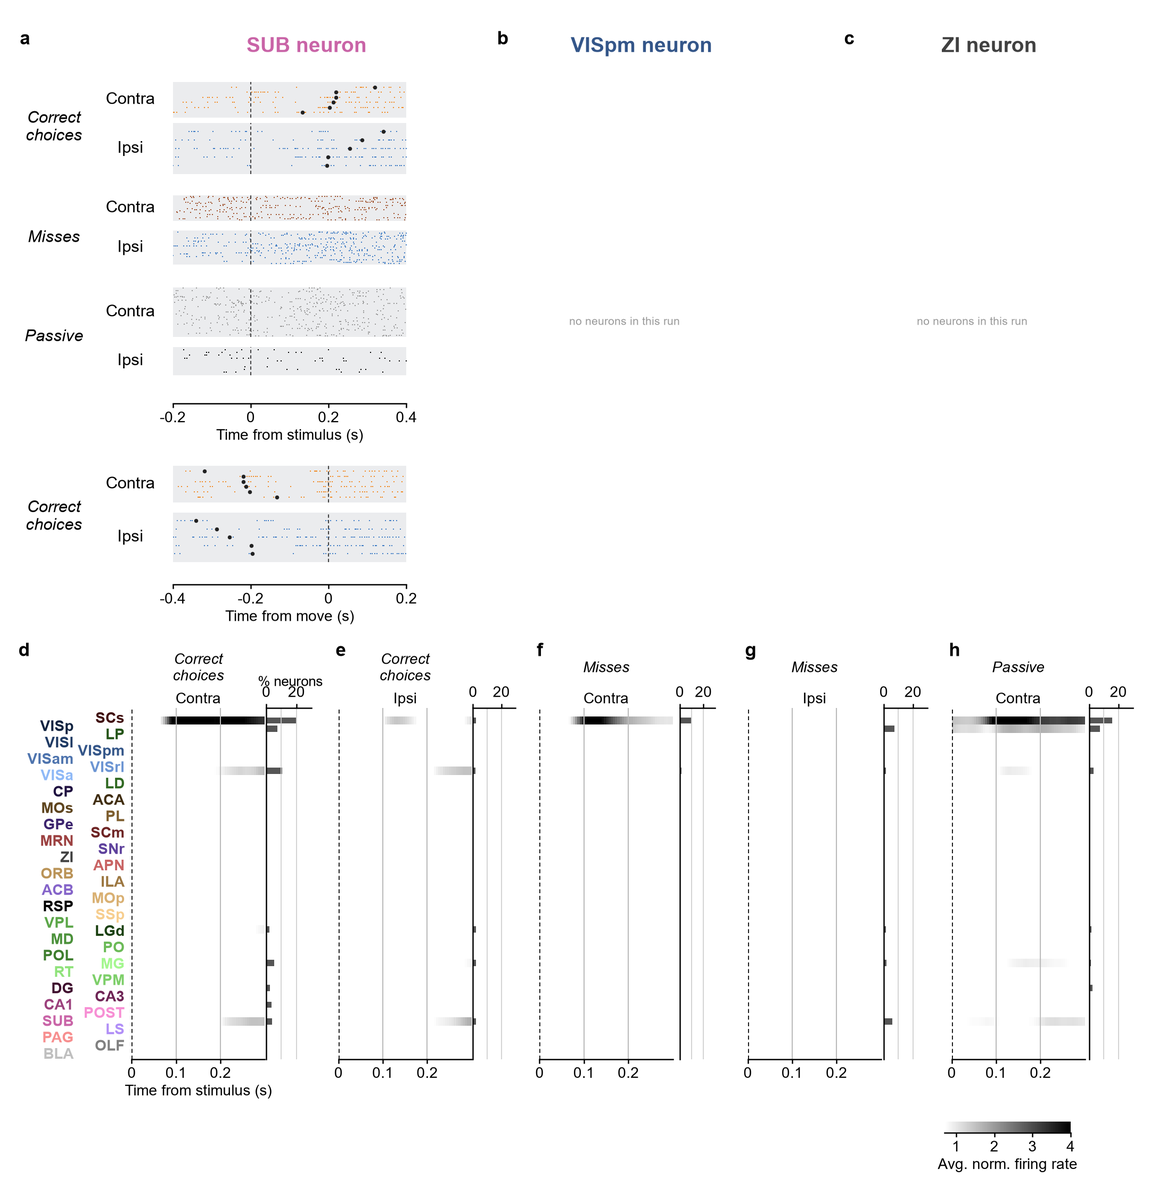

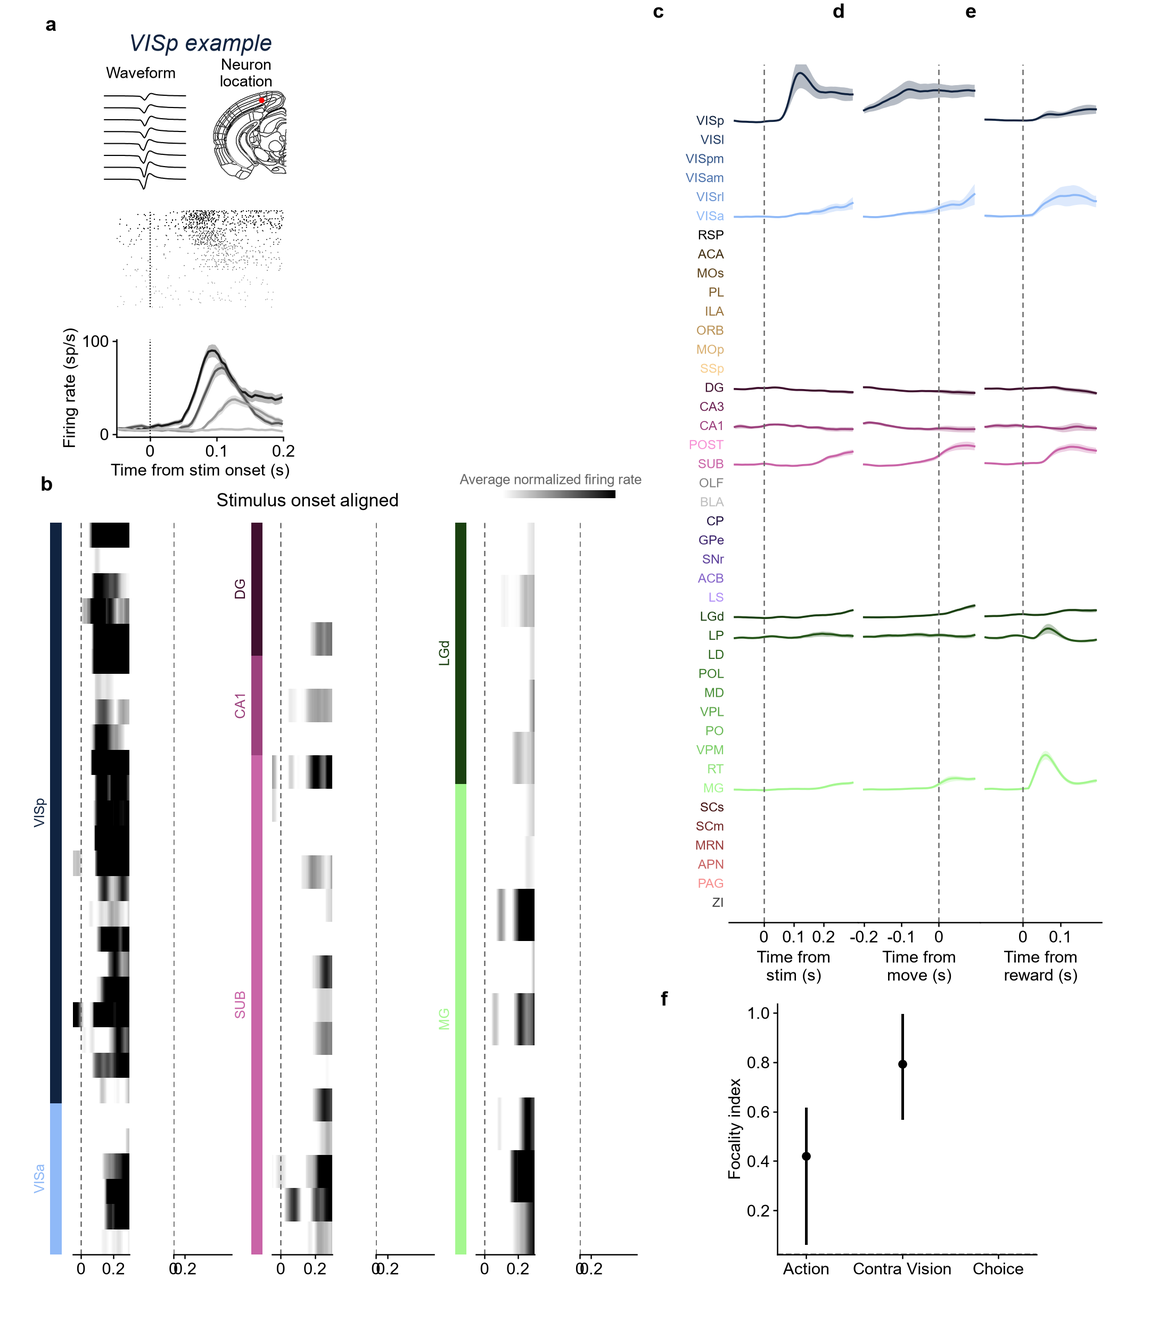

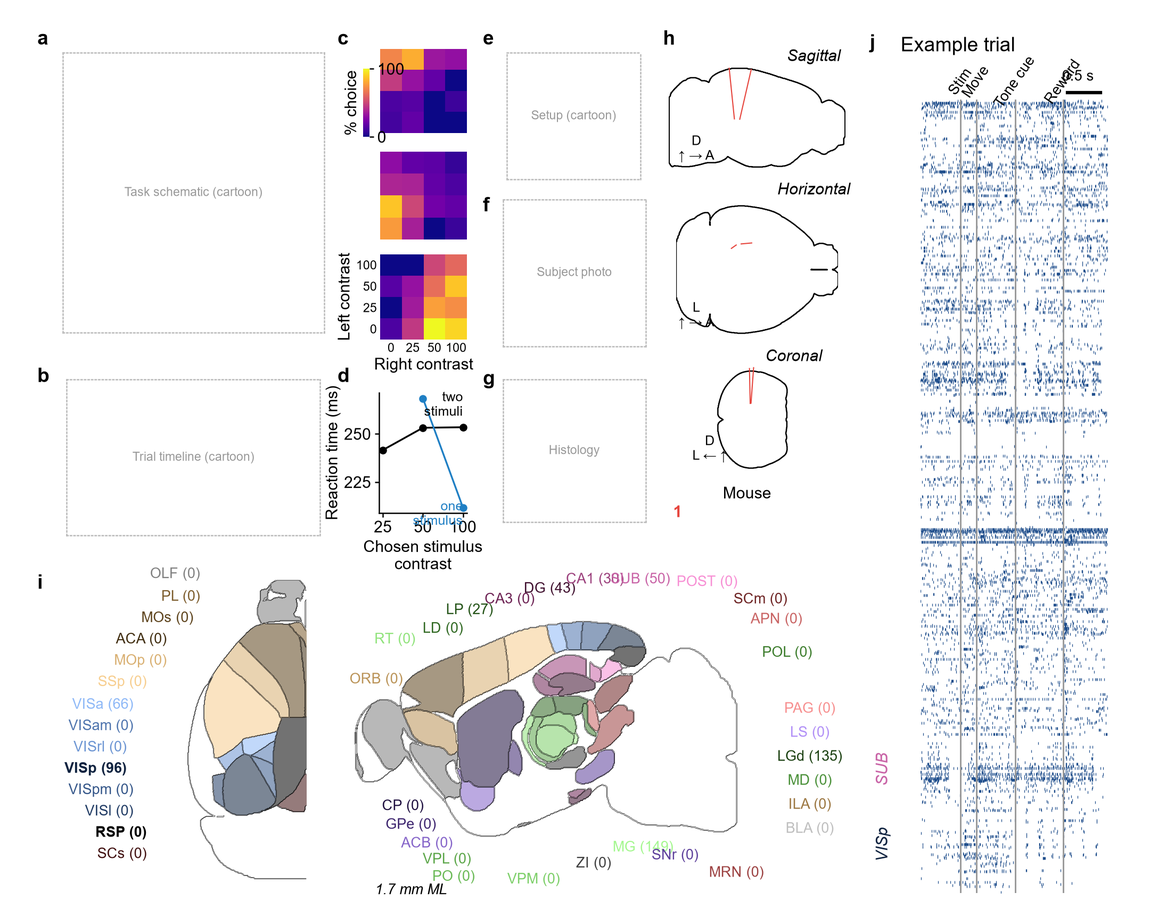

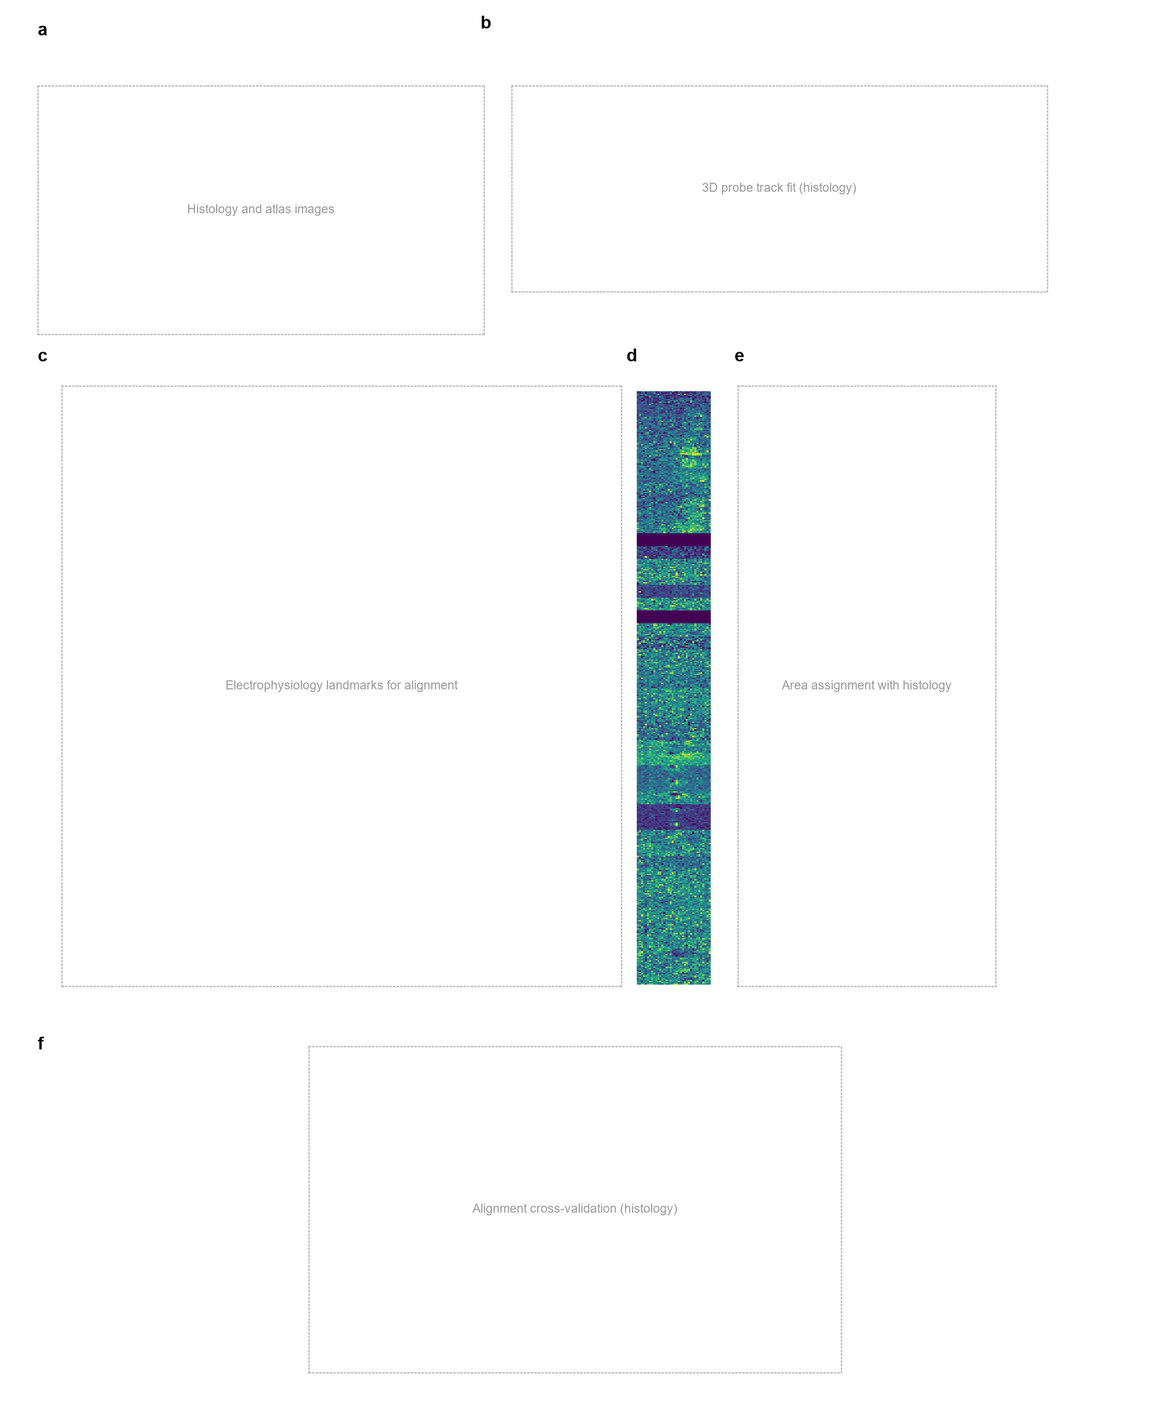

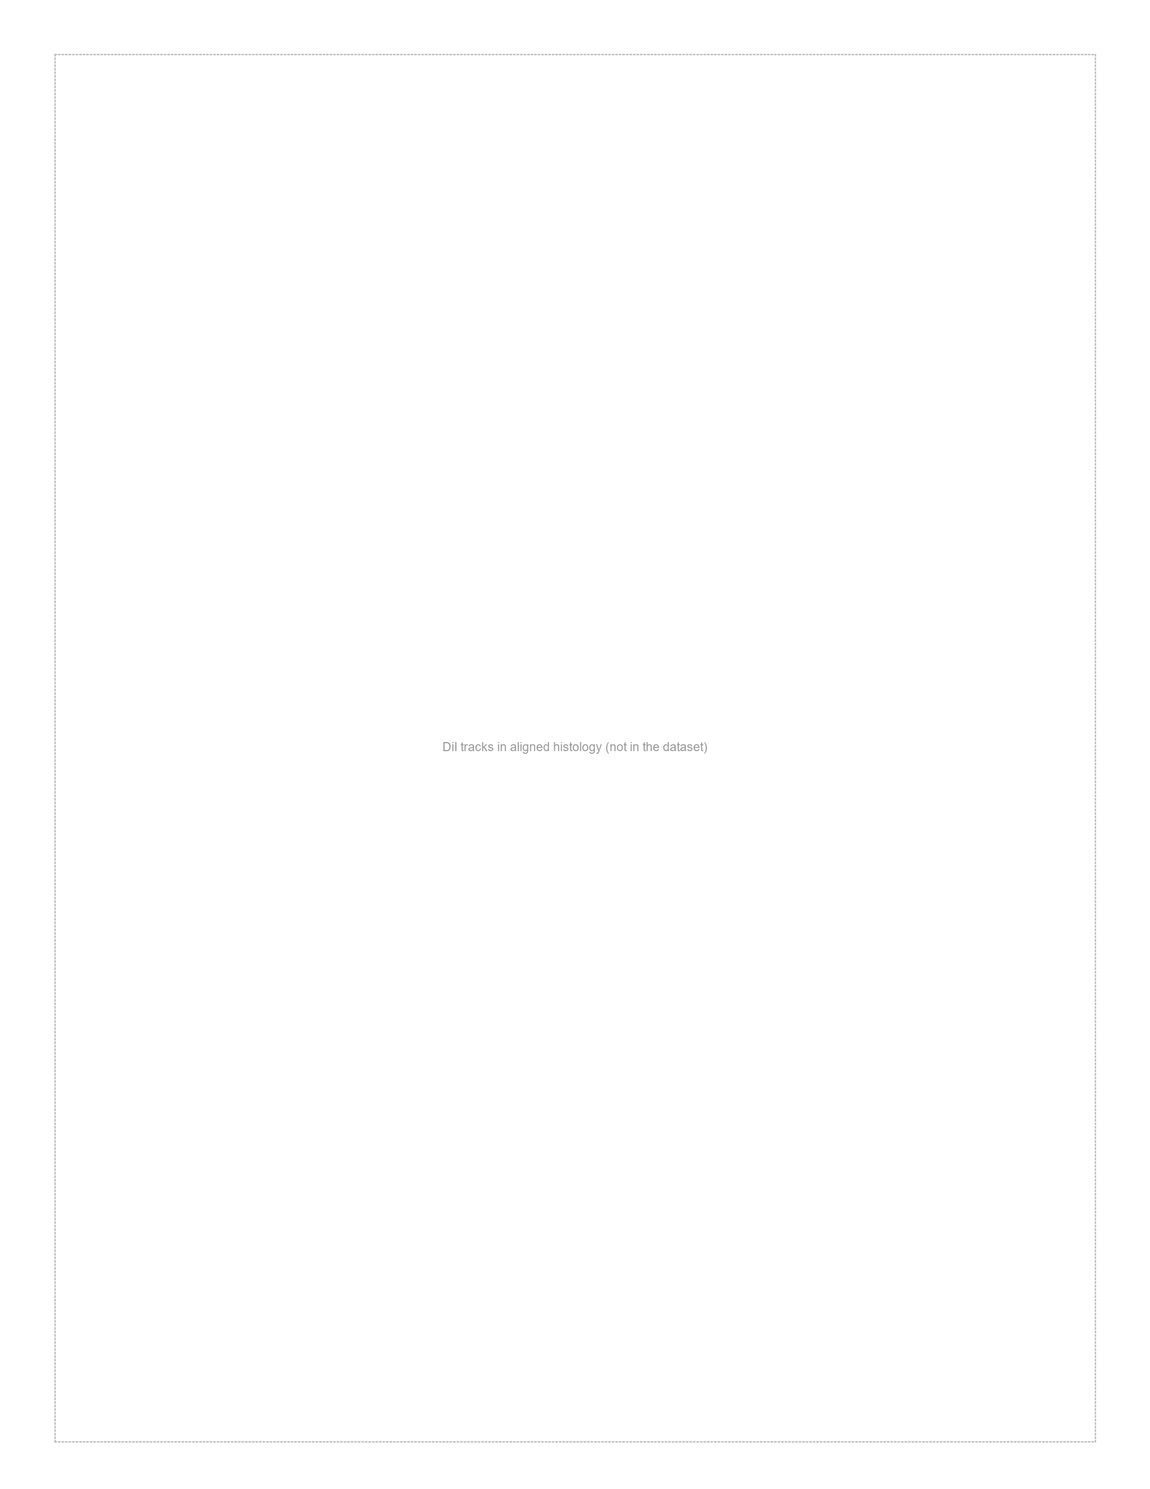

In [26]:
figure("fig2", "ext4", "fig1", "ext2", "ext3")

In [27]:
chosen = store.load_json(cfg.results / "example_neurons.json")
pd.DataFrame(chosen).T.head(24)

,session,cluster,choice_ve
fig2a,Moniz_2017-05-16,849,NaN
fig4a_vis,Moniz_2017-05-16,716,NaN
ext4_visp,Moniz_2017-05-16,1096,NaN
assign_raster_VISp,Moniz_2017-05-16,1096,NaN
assign_4e_VISp_contra,Moniz_2017-05-16,967,0.009884
assign_4e_VISp_ipsi,Moniz_2017-05-16,871,0.001361
assign_raster_LGd,Moniz_2017-05-16,507,NaN
assign_4e_LGd_contra,Moniz_2017-05-16,307,-0.0
assign_4e_LGd_ipsi,Moniz_2017-05-16,186,0.001633
assign_raster_LP,Moniz_2017-05-16,1118,NaN


## 9. Choice signals: decoding and jPECC

### Population decoding

From residuals with the tested kernel removed, an L1-regularized logistic regression finds a coding direction on training trials: 50 to 150 ms after the stimulus for Vision, and -50 to 0 ms before movement for Action and Choice. Test trials are projected at every time point, and decoding is the difference between the two groups' mean projections.

For Action, trials without a movement get a pseudo onset drawn from the session's real onsets, with a fixed seed.

For Fig 4c each recording is divided by **its group's mean at choice time** (t = 0), not by its own value. Dividing each recording by its own value would force the s.e.m. to zero at t = 0, and the paper's figure has a band there.

decoding: 5.15 s, peak 1.071 GB
{'vision_contra': 8, 'vision_ipsi': 8, 'action': 8, 'choice': 8} regions with a decoder


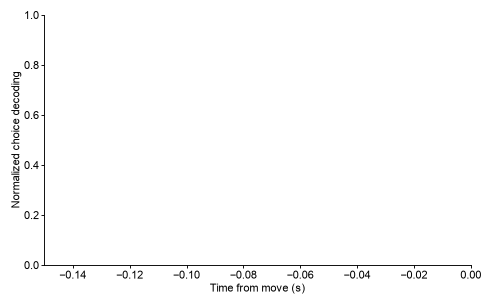

In [28]:
run("decoding")
curves = {}
for s in sessions:
    for k, v in store.load(cfg.results / "decoding" / f"{s}.npz").items():
        key, r = k.split("|")
        curves.setdefault(key, {}).setdefault(r, []).append(v)
print({k: len(v) for k, v in curves.items()}, "regions with a decoder")
off = decoding.OFFSETS["move"]
mats, groups = [], []
for name, regs in (("Frontal", C.FRONTAL), ("Midbrain", C.MIDBRAIN), ("CP", C.STRIATUM)):
    for r in regs:
        for v in curves.get("choice", {}).get(r, []):
            mats.append(v), groups.append(name)
fig, ax = plt.subplots(figsize=(4.5, 2.8))
if mats:
    norm = decoding.normalize_groups(np.array(mats), groups, -1)
    for g_name in sorted(set(groups)):
        q = norm[np.array(groups) == g_name]
        ax.plot(off, np.nanmean(q, 0), label=f"{g_name} (n={len(q)})")
    if len(set(groups)) > 1 and len(mats) > 3:
        print(decoding.timing_anova(norm[:, off >= -0.15], groups, off[off >= -0.15]))
    ax.legend(frameon=False)
ax.set_xlim(-0.15, 0), ax.set_xlabel("Time from move (s)"), ax.set_ylabel("Normalized choice decoding")
plt.tight_layout()

### jPECC

Joint peri-event canonical correlation asks when two populations share activity. At each pair of times, activity in each region group is reduced to 10 PCs and a ridge CCA (lambda 0.5) is trained on 9 of 10 folds. The test trials' projections are then correlated. An off-diagonal bias means one area leads the other.

The asymmetry index compares the two sides of the diagonal within ±50 ms. It is positive when the first area leads.

In [29]:
run("jpecc")
rows = []
for s in sessions:
    z = store.load(cfg.results / "jpecc" / f"{s}.npz")
    for k in z:
        if k.startswith("r|"):
            _, ev, a_, c_ = k.split("|")
            rows.append(dict(session=s, event=ev, pair=f"{a_} vs {c_}", peak_r=round(float(z[k].max()), 2), mean_asymmetry=round(float(np.nanmean(jpecc.asymmetry(np.array(z[k], float)))), 3)))
pd.DataFrame(rows) if rows else "no session here has two region groups with 5 or more neurons"

jpecc: 0.02 s, peak 0.0 GB


'no session here has two region groups with 5 or more neurons'

### Figures: Fig 4 (choice) and Ext 8 (jPECC)

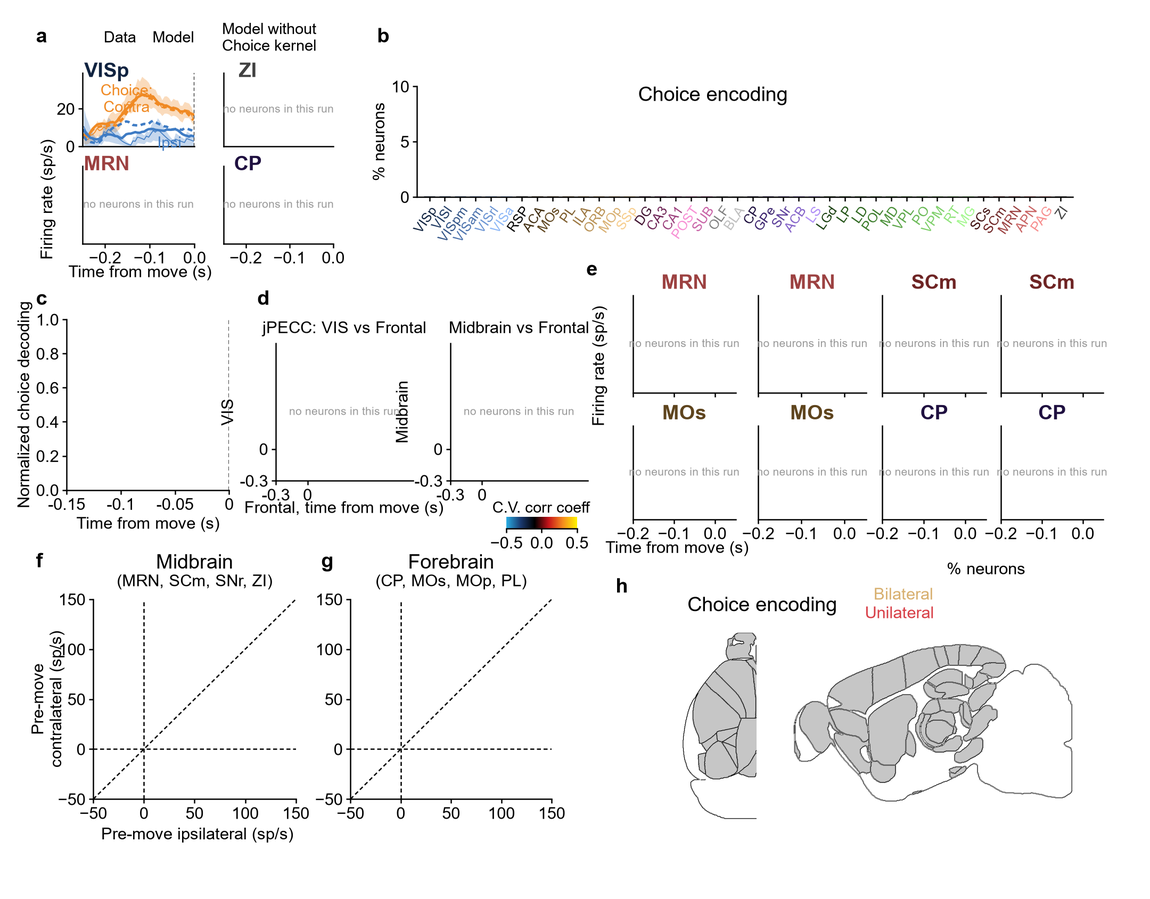

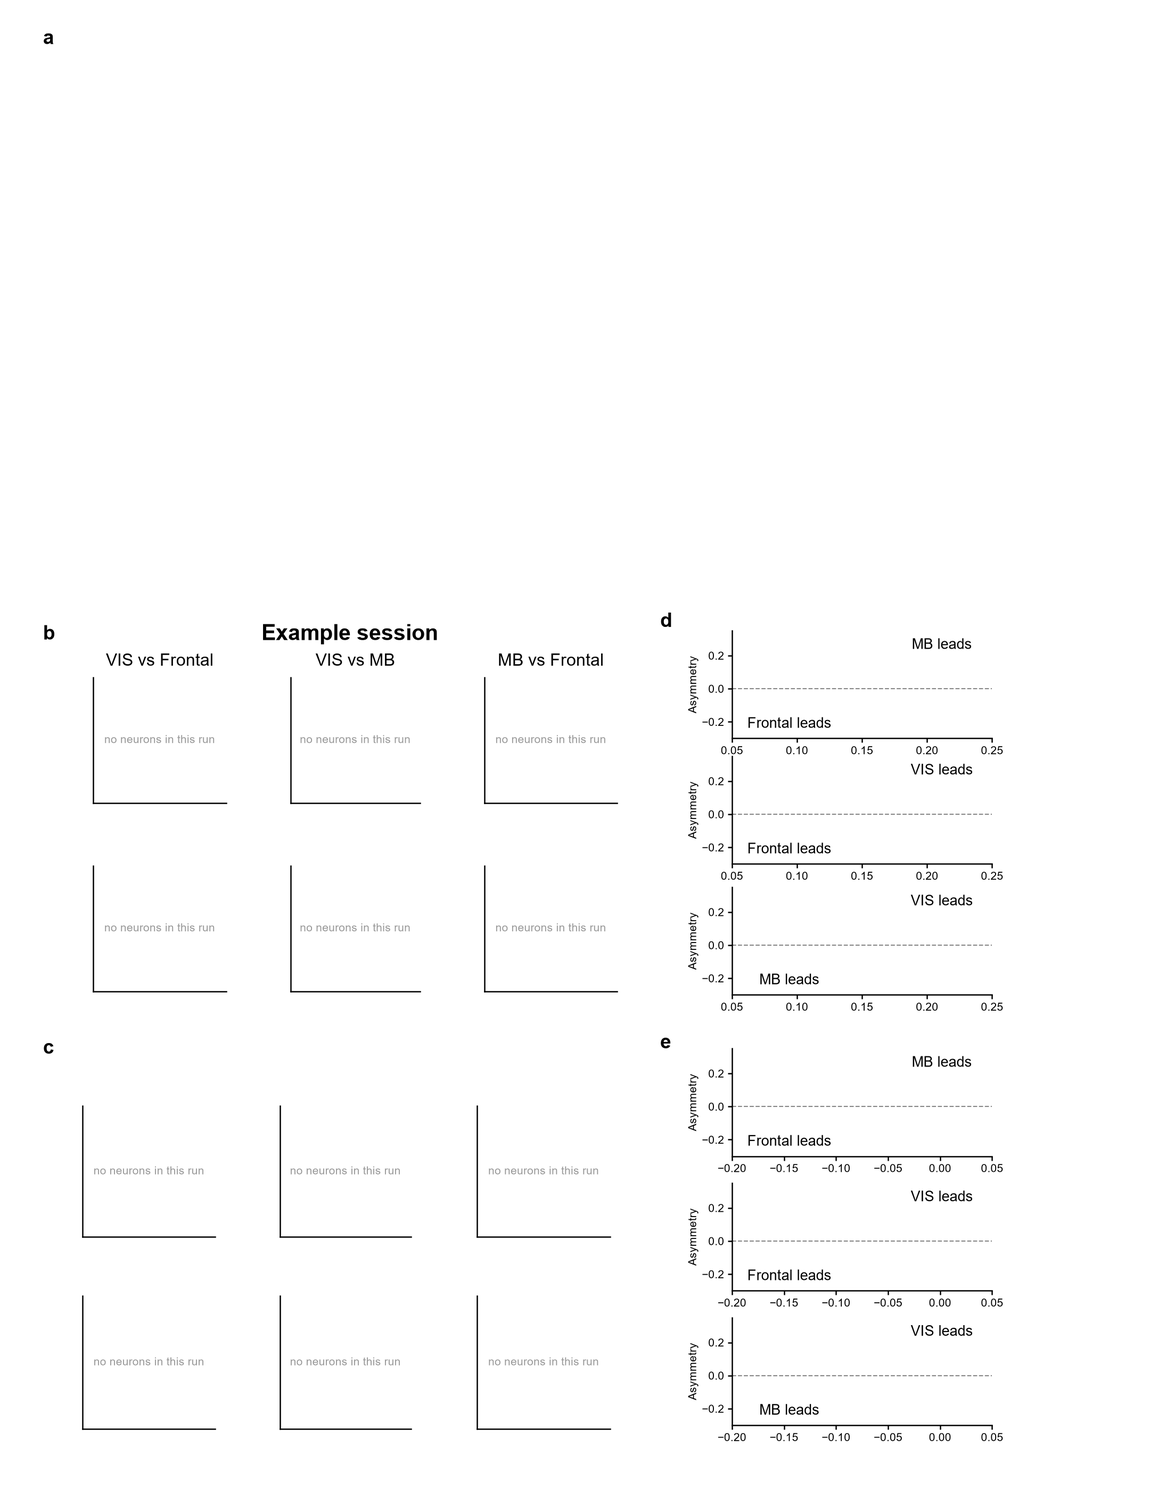

In [30]:
figure("fig4", "ext8")

## 10. Choice and detect probability

Combined-conditions choice probability (ccCP) asks whether a neuron's count differs between Left and Right trials for the *same* stimulus. Mann-Whitney numerators and denominators are summed across the 16 stimulus conditions, so all trials contribute. Detect probability (DP) does the same for Go against NoGo.

Significance comes from 2,000 shuffles of the labels within each condition. The shuffles are computed as one matrix product, with the same labels across neurons and bins, which needs about 0.16 GB where direct indexing needed over 17 GB. Sharing labels keeps each neuron's p-value valid, although shuffle noise is correlated across neurons.

Counts use a 100 ms box, so the bins centered on 0 and 0.2 s are the paper's -50 to +50 ms and +150 to +250 ms windows.

In [31]:
run("cccp")
rows = []
for s in sessions:
    z = store.load(cfg.results / "cccp" / f"{s}.npz")
    if len(z["ids"]):
        reg = res.base(s)["n_region"][z["ids"]]
        t_mv = np.arange(int(round(0.55 / cccp.STEP)) + 1) * cccp.STEP - 0.3
        i0, i2 = int(np.argmin(np.abs(t_mv))), int(np.argmin(np.abs(t_mv - 0.2)))
        sig = lambda p: (p < 0.025) | (p > 0.975)
        for r in np.unique(reg):
            d = dict(session=s, region=r, neurons=int((reg == r).sum()))
            if bool(z["dp_ok"]):
                d["DP % (-50 to 50 ms)"] = round(100 * sig(z["dp_move_p"][i0, reg == r]).mean(), 1)
            if bool(z["cp_ok"]):
                d["CP % (-50 to 50 ms)"] = round(100 * sig(z["cp_move_p"][i0, reg == r]).mean(), 1)
                d["CP % (+150 to 250 ms)"] = round(100 * sig(z["cp_move_p"][i2, reg == r]).mean(), 1)
            rows.append(d)
pd.DataFrame(rows)

cccp: 10.95 s, peak 1.386 GB


,session,region,neurons,DP % (-50 to 50 ms),CP % (-50 to 50 ms),CP % (+150 to 250 ms)
0,Moniz_2017-05-16,CA1,30,13.3,0.0,0.0
1,Moniz_2017-05-16,DG,43,18.6,0.0,0.0
2,Moniz_2017-05-16,LGd,135,23.7,1.5,6.7
3,Moniz_2017-05-16,LP,27,14.8,3.7,3.7
4,Moniz_2017-05-16,MG,149,24.2,2.0,3.4
5,Moniz_2017-05-16,SUB,50,54.0,2.0,2.0
6,Moniz_2017-05-16,VISa,66,33.3,1.5,3.0
7,Moniz_2017-05-16,VISp,96,14.6,0.0,1.0


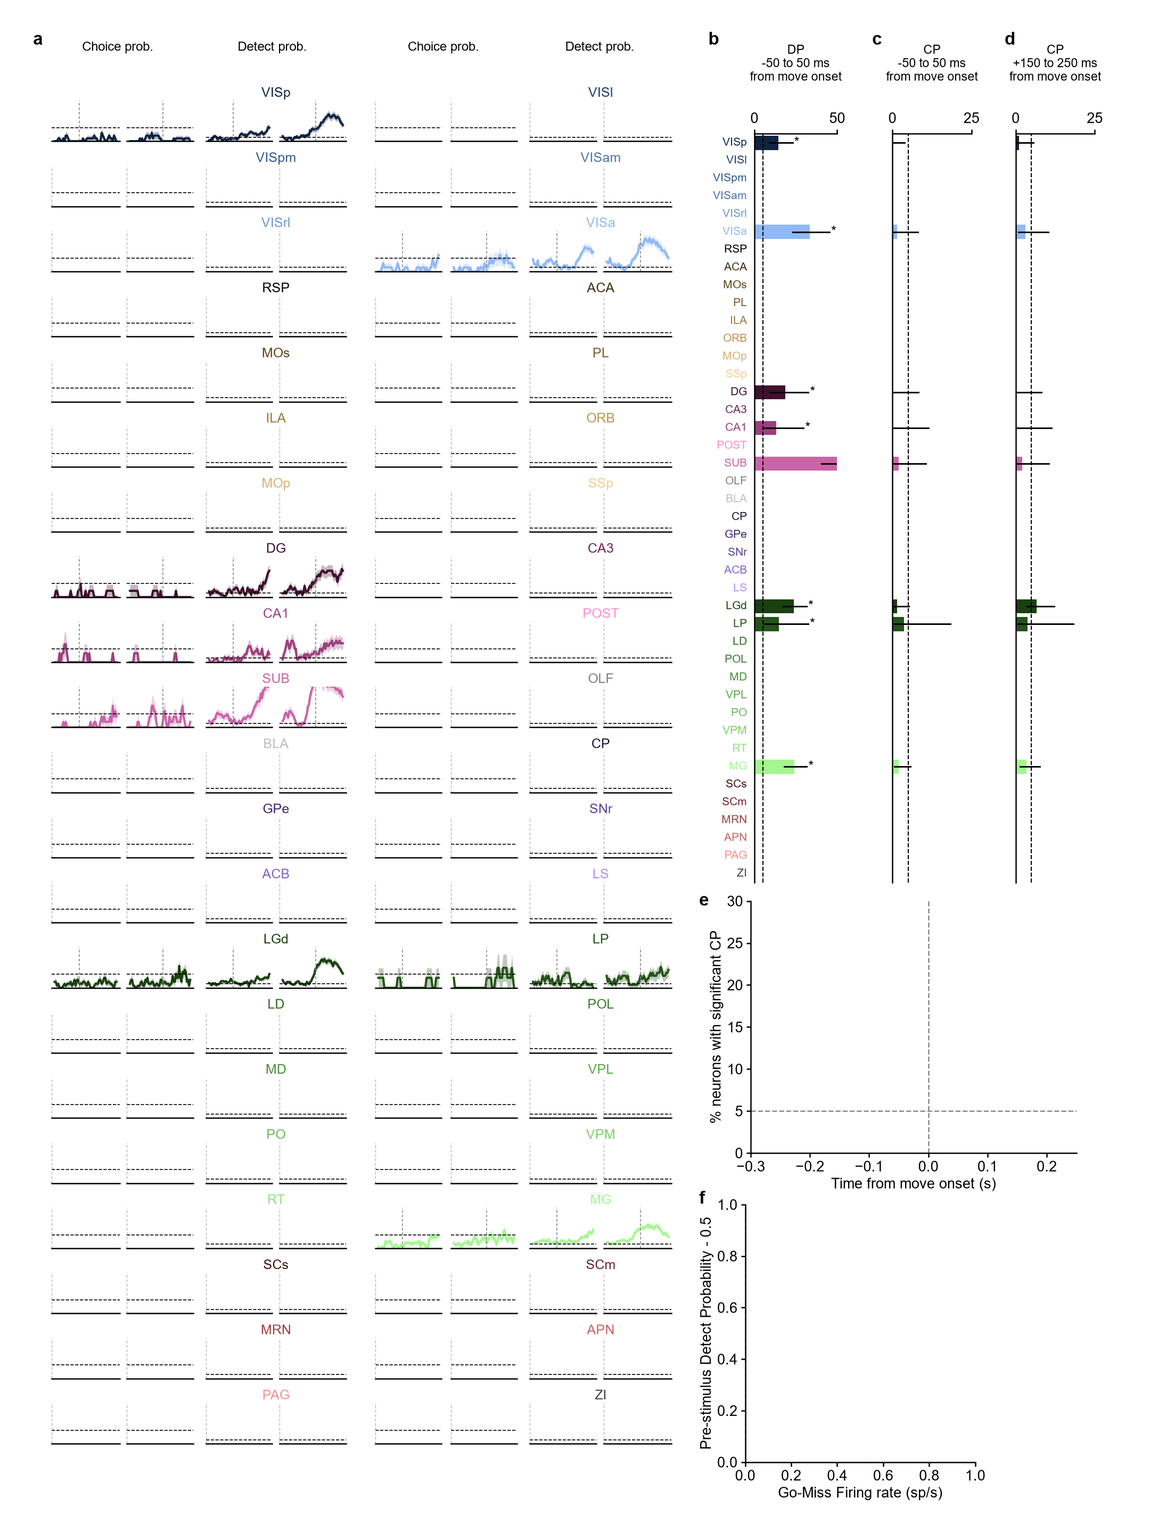

In [32]:
figure("ext7")

## 11. Task engagement

Two pre-stimulus definitions are used, and they should not be mixed up:

| Analysis | Window | Rate |
|---|---|---|
| Nested ANOVA (Ext 9a) | -250 to -50 ms | $\log_{10}(x + 1)$ per neuron, excluding trials with movement in the window |
| Engagement vector and index (Fig 5e-f, Ext 9b-k) | -200 to 0 ms | sp/s |

The ANOVA has factors condition, session, and neuron nested in session. Regions pass at p < 0.0012 (0.05/42). The engagement vector uses neurons in those regions:

$$x_n = \overline{f_n^{\,task}}(-0.2 < t < 0) - \overline{f_n^{\,passive}}(-0.2 < t < 0), \qquad \text{index}_i = \frac{x}{\|x\|} \cdot f^{\,i}$$

The index is compared between Go and Miss trials matched for contra contrast. A logistic GLM then tests whether it adds to pupil, motion, previous reward and inter-trial interval, with squared pupil and motion terms.

The paper gives no rule for the short and long ITI split or the Ext 9k vectors, so those are within-session median splits, and it does not name its 5 rejected pupil recordings, so pupil panels use all sessions.

In [33]:
run("engagement_sessions", "engagement")
e = store.load(cfg.results / "engagement.npz")
rows = [dict(region=k.split("|")[1], F=v[0], p=v[1], log_difference=v[2], sem=v[3], neurons=int(v[4])) for k, v in e.items() if k.startswith("anova|")]
anova = pd.DataFrame(rows).sort_values("p")
print("significant regions:", [str(r) for r in e["significant"]])
anova.round(4)

engagement_sessions: 0.24 s, peak 1.156 GB
engagement: 0.02 s, peak 0.0 GB
significant regions: ['LGd', 'LP', 'MG', 'SUB', 'VISp']


,region,F,p,log_difference,sem,neurons
3,LP,40.5146,0.0000,-0.2213,0.0348,27
7,VISp,17.1783,0.0001,-0.1213,0.0293,96
2,LGd,14.0885,0.0003,0.1371,0.0365,135
5,SUB,14.8310,0.0003,-0.1885,0.0489,50
4,MG,11.0310,0.0011,-0.0824,0.0248,149
6,VISa,10.8223,0.0016,-0.1131,0.0344,66
1,DG,3.3889,0.0727,0.1007,0.0547,43
0,CA1,0.7380,0.3974,-0.0572,0.0665,30


70 contrast-matched trials, Go-Miss index difference per session: [3.17] (paper mean 8.42)


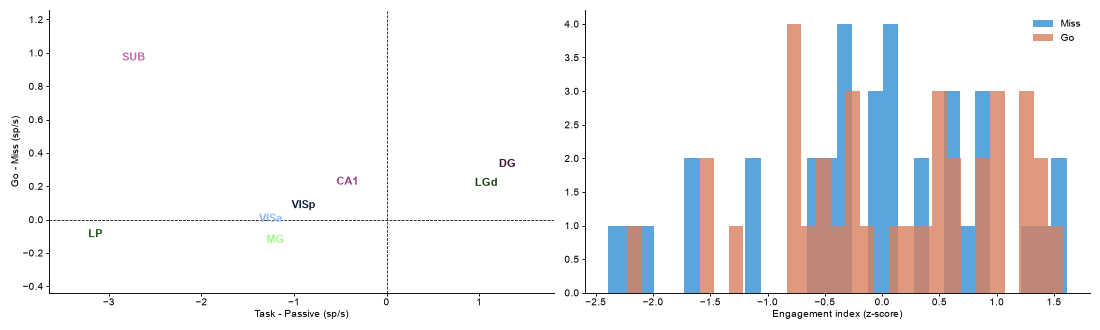

In [34]:
tab = e["trial_table"]
print(f"{len(tab)} contrast-matched trials, Go-Miss index difference per session: {np.round(e['ei_diff'], 2)} (paper mean 8.42)")
names = [str(r) for r in e["region_names"]]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for r, a_, b_ in zip(names, e["task_passive"], e["go_miss"]):
    axes[0].text(a_, b_, r, color=REGION_COLORS[r], ha="center", fontsize=7, fontweight="bold")
axes[0].set_xlim(e["task_passive"].min() - 0.5, e["task_passive"].max() + 0.5), axes[0].set_ylim(np.nanmin(e["go_miss"]) - 0.3, np.nanmax(e["go_miss"]) + 0.3)
axes[0].axhline(0, color="k", ls="--", lw=0.5), axes[0].axvline(0, color="k", ls="--", lw=0.5), axes[0].set_xlabel("Task - Passive (sp/s)"), axes[0].set_ylabel("Go - Miss (sp/s)")
if len(tab):
    axes[1].hist(tab[tab[:, 1] == 0, 0], bins=30, color="#5aa5dc", label="Miss"), axes[1].hist(tab[tab[:, 1] == 1, 0], bins=30, color="#d9805e", alpha=0.8, label="Go")
    axes[1].set_xlabel("Engagement index (z-score)"), axes[1].legend(frameon=False)
plt.tight_layout()

### Figures: Fig 5 (engagement), Ext 6 (population rates) and Ext 9 (statistics)

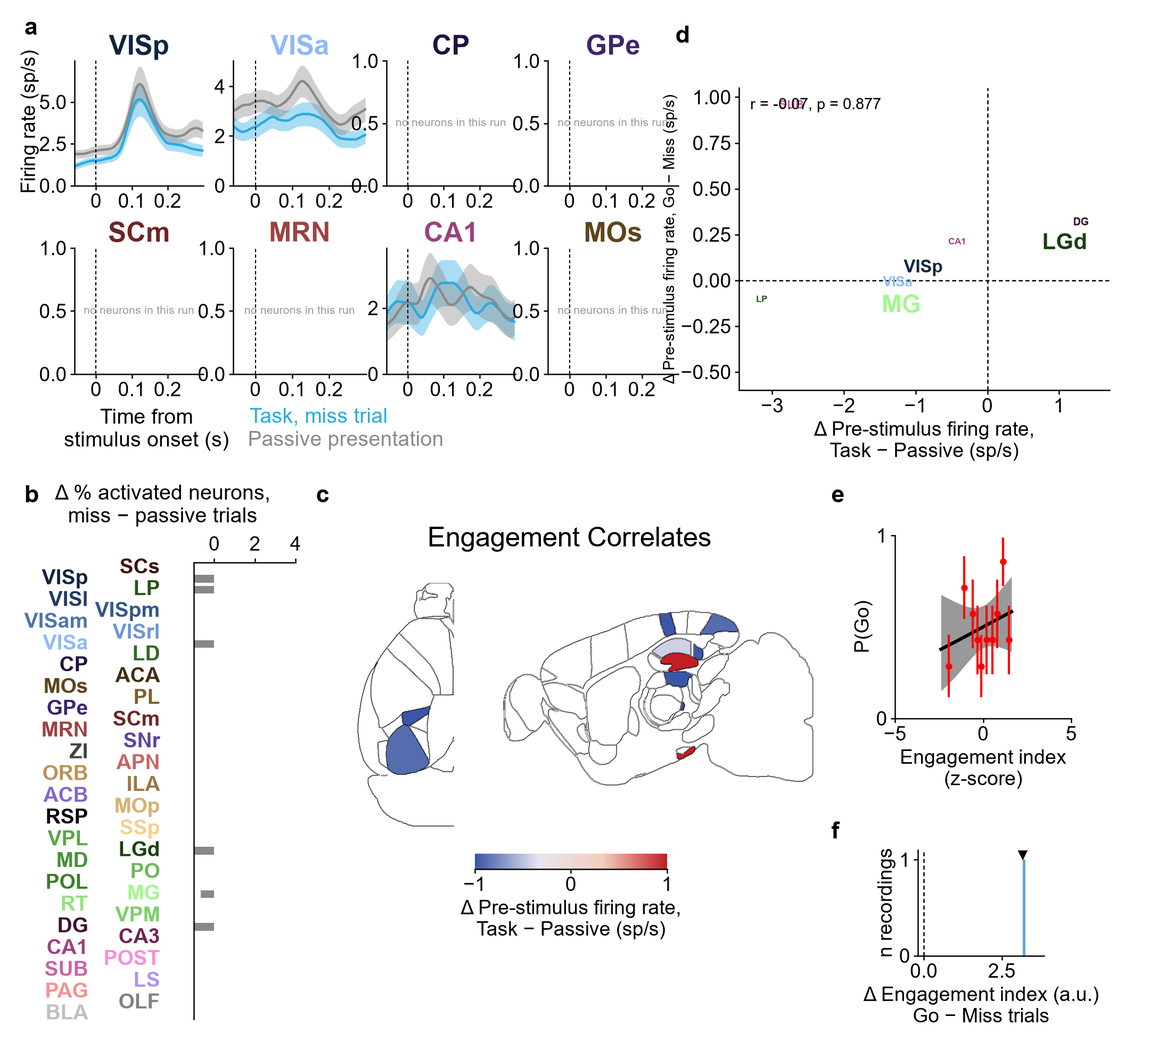

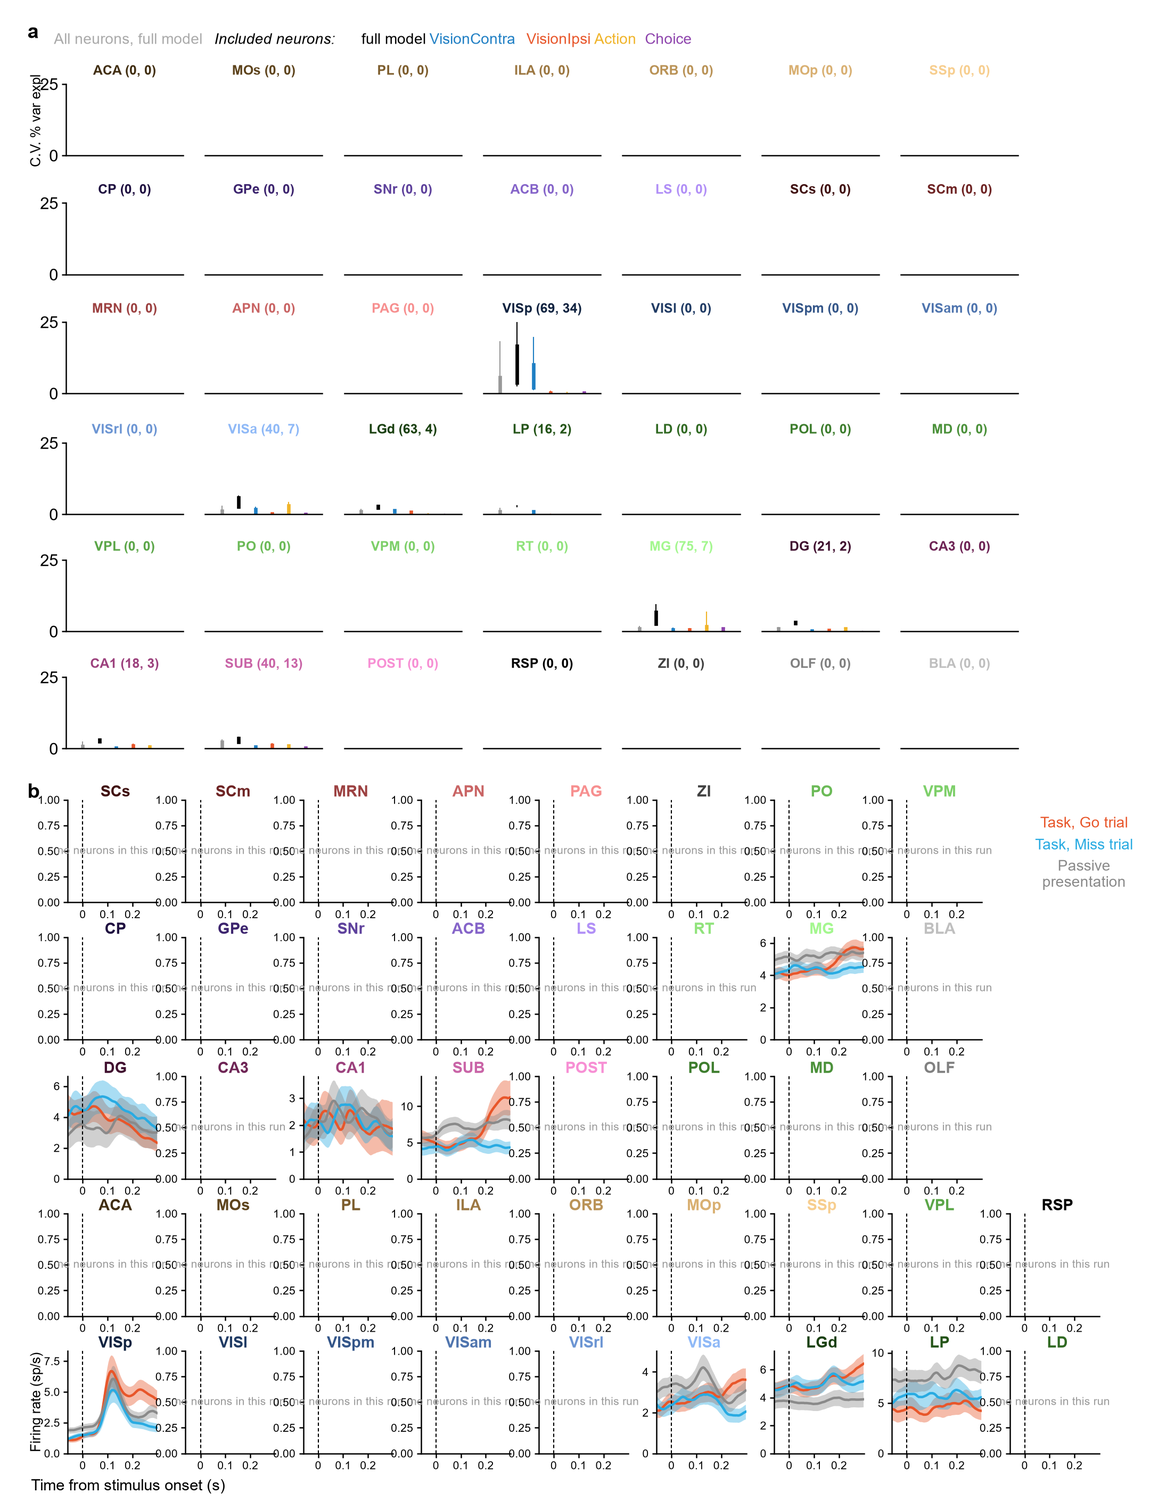

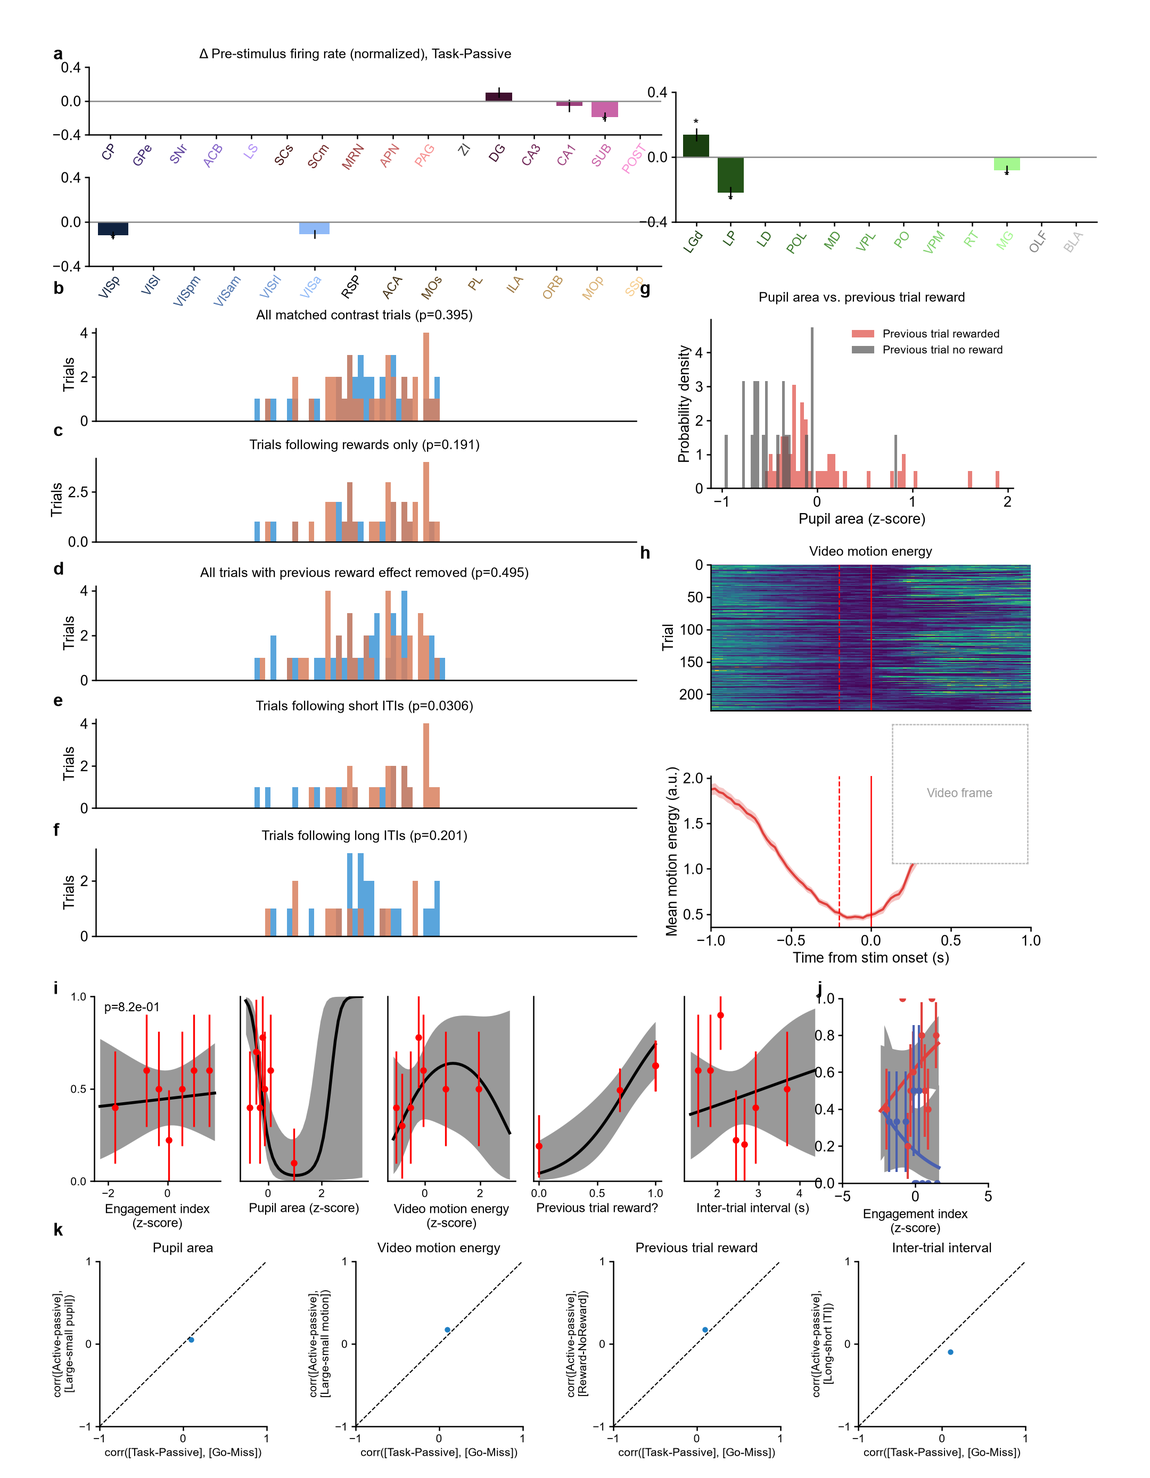

In [35]:
figure("fig5", "ext6", "ext9")

## 12. Assignment figures: VISp, LGd, LP

The four plot types of the assignment, redone for these three regions.

- **Fig 2a-c style:** rasters of one neuron per region, chosen for the largest contra stimulus response from 50 to 150 ms.
- **Fig 4e style:** rates aligned to movement. Neurons are ranked by nested Choice variance explained, with the top row preferring contra and the bottom row ipsi. Each title says whether the neuron passes 2%.
- **Fig 5a style:** population mean for Miss and Passive trials, contrast matched.
- **Ext 6b style:** population mean for Go, Miss and Passive trials, contrast matched.

Two results should not be misread:

- VISp, LGd and LP have few or no choice-selective neurons. Contra and ipsi curves can still separate in the Fig 4e style, because contra choices mostly follow contra stimuli, so that separation can be visual.
- The paper reports that recorded LGd neurons' receptive fields did not overlap the task stimuli, so LGd visual responses may be weak.

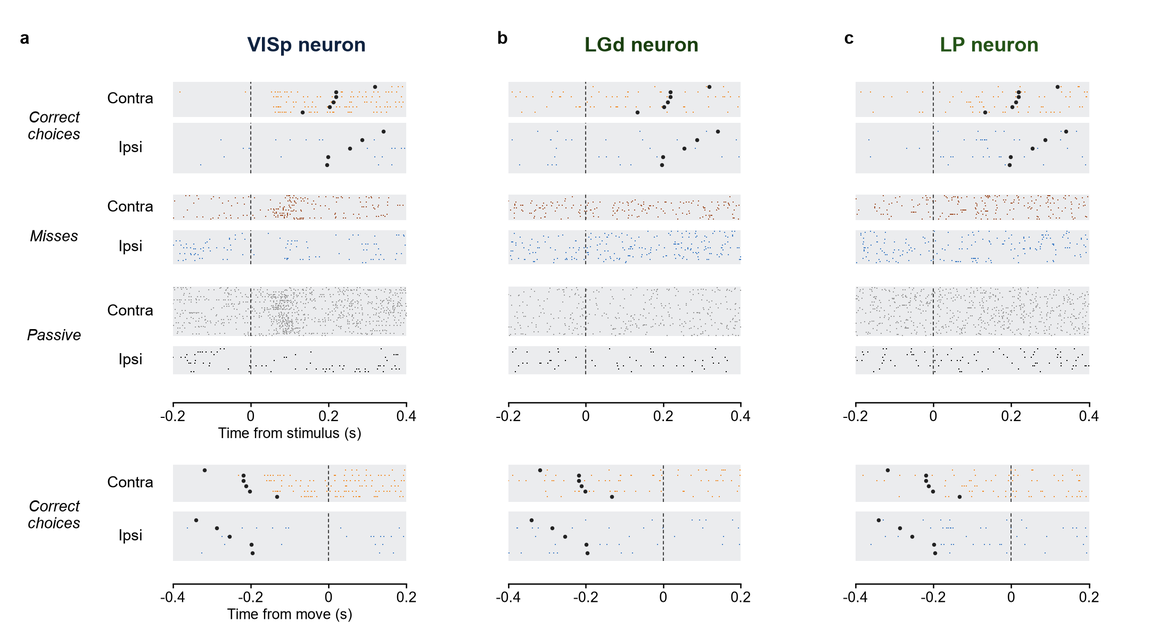

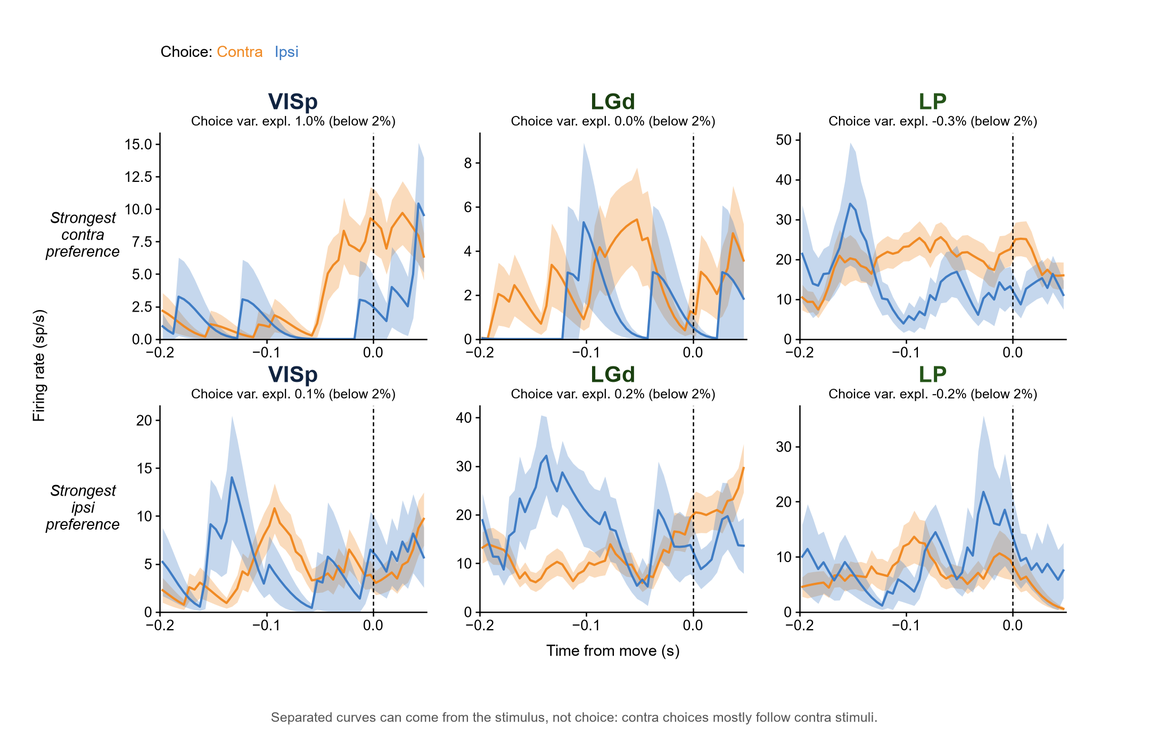

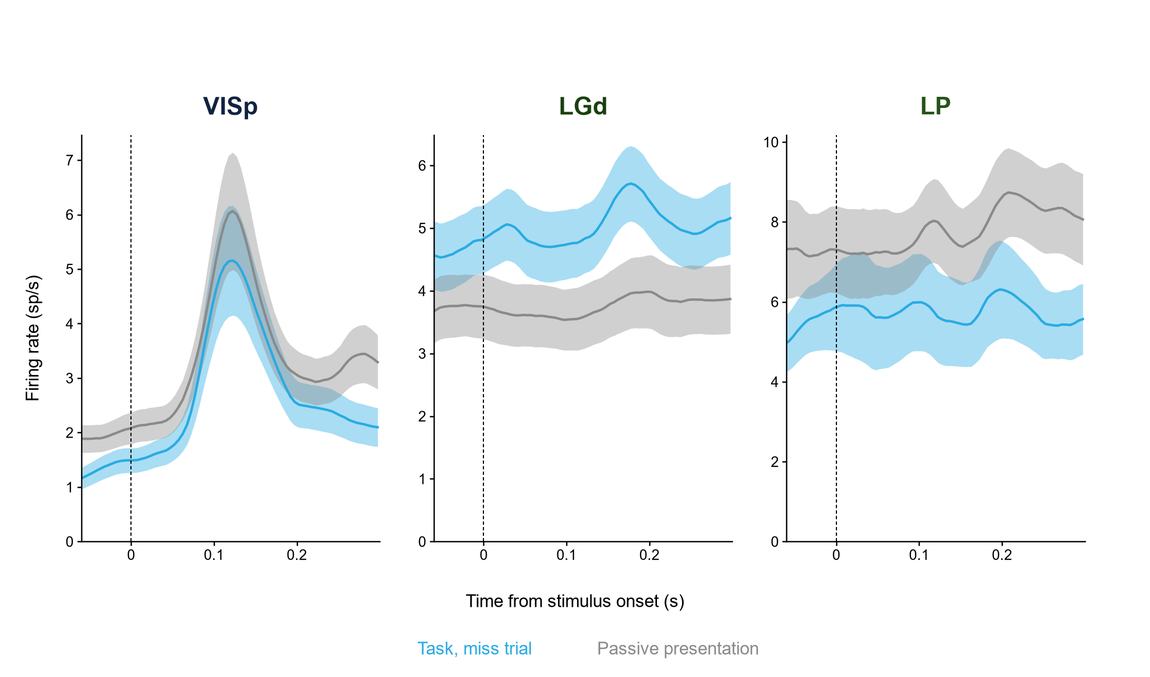

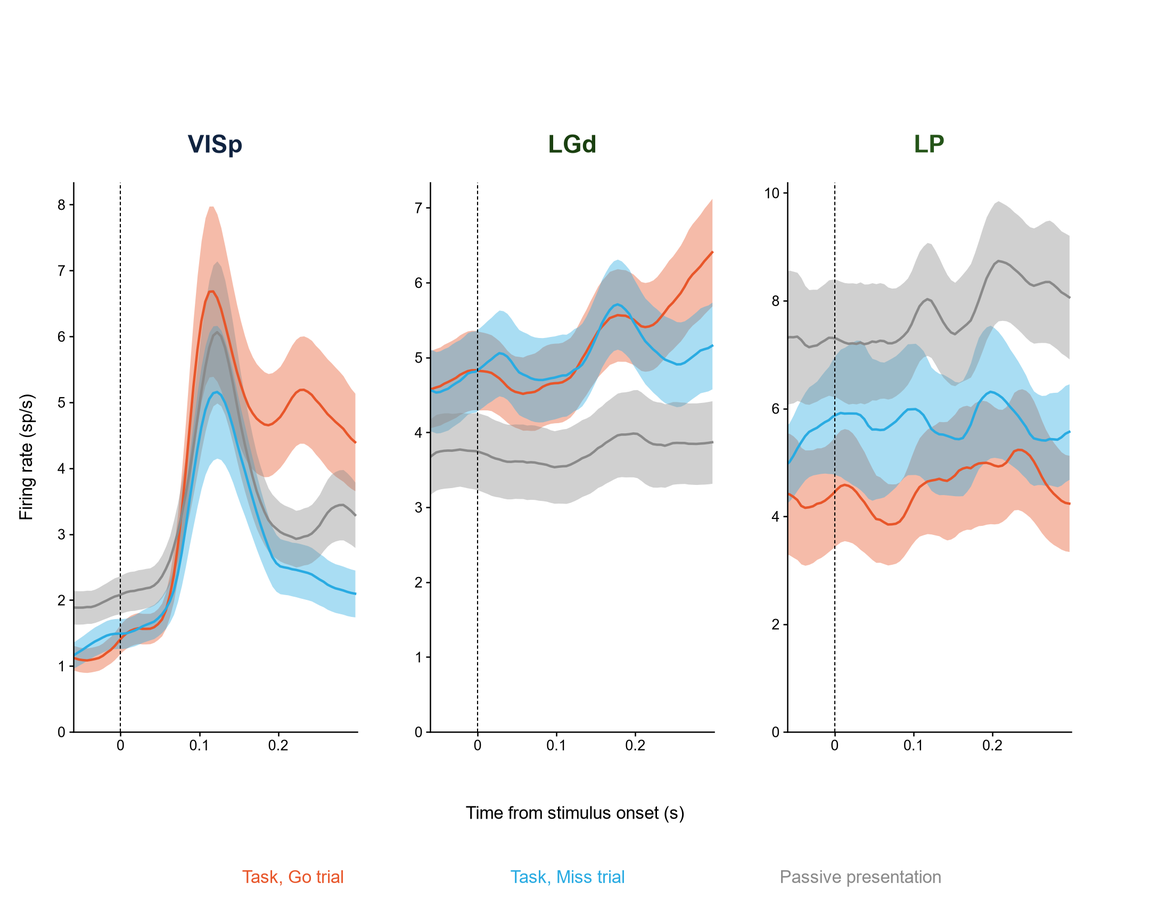

In [36]:
failed = make_all(cfg, {"assignment"})
assert not failed, failed
for name in ("assignment_fig2abc_rasters", "assignment_fig4e_choice", "assignment_fig5a_miss_passive", "assignment_ext6b_go_miss_passive"):
    show(name, "assignment")

In [37]:
rows = []
for r in C.ASSIGNMENT_REGIONS:
    s_ = n[n.region == r]
    q = t[t.region == r]
    rows.append(dict(region=r, neurons=len(s_), recordings=s_.session.nunique(), responsive=int(s_.responsive.sum()), regression=len(q), passing_2pct=int((q.ve >= 0.02).sum()),
                     vision_contra=int((q.vision_contra > 0.02).sum()), action=int((q.action > 0.02).sum()), choice=int((q.choice > 0.02).sum())))
pd.DataFrame(rows).set_index("region")

,neurons,recordings,responsive,regression,passing_2pct,vision_contra,action,choice
region,,,,,,,,
VISp,96,1,50,69,34,26,2,0
LGd,135,1,41,63,4,0,0,0
LP,27,1,12,16,2,0,0,0


## 13. Comparison with the paper

`report_vs_paper.md` lists the paper's numbers beside ours, the sessions left out, Extended Data Table 1, and every known difference from the paper. In session mode the numbers only show that the report works. Exact matches are not expected for anything that depends on random splits or a different solver.

In [38]:
failed = make_all(cfg, {"report"})
assert not failed, failed
display(Markdown((cfg.output / "report_vs_paper.md").read_text(encoding="utf8")))

# Paper against this run

Sessions in this run: 1 of 39.

| Quantity | Paper | Ours |
|---|---|---|
| Included trials | 9538 | 225 |
| Neurons | 29134 | 792 |
| Localized neurons | 22458 | 596 |
| Modulated neurons | 13,466 (60.0%) | 290 (48.7%) |
| Sessions with contrast-matched trials | 34 of 39 | 1 of 1 |
| Sessions in CP analysis | 33 of 39 | 1 of 1 |
| Sessions in DP analysis | not stated | 1 of 1 |
| Shuffle false positives | 0.33% | 0.00% |
| Focality: action, contra vision, choice | 0.040, 0.069, 0.079 | 0.420, 0.793, nan |
| Fig 5d correlation | r = 0.46, p = 0.002 | r = -0.07, p = 0.877 |
| Mean engagement index difference | 8.42 | 3.17 (n = 1) |
| Ext 7f with Go-Miss, DP-qualified sessions (1) | r = 0.69 | r = 0.78 |
| Ext 7f with Task-Passive, DP-qualified sessions | r = 0.48 | r = -0.01 |
| Ext 7f with Go-Miss, 33-session CP subset sessions (1) | r = 0.69 | r = 0.78 |
| Ext 7f with Task-Passive, 33-session CP subset sessions | r = 0.48 | r = -0.01 |

## Sessions left out

Contrast matching: none
CP: none
DP: none

## Two-sided and one-sided significance (Fig 2d-h, Fig 5b)

| Condition | |z|>4 | z>4 |
|---|---|---|
| contra_correct | 7.2% | 7.2% |
| ipsi_correct | 1.7% | 1.7% |
| contra_miss | 1.8% | 1.8% |
| ipsi_miss | 1.8% | 1.8% |
| contra_passive | 4.0% | 4.0% |

## Extended Data Table 1

| Region | Paper total | Ours | Paper responsive | Ours |
|---|---|---|---|---|
| ACA | 608 | 0 | 395 | 0 |
| ACB | 255 | 0 | 152 | 0 |
| APN | 235 | 0 | 177 | 0 |
| BLA | 261 | 0 | 107 | 0 |
| CA1 | 1129 | 30 | 494 | 10 |
| CA3 | 438 | 0 | 243 | 0 |
| CP | 914 | 0 | 524 | 0 |
| DG | 711 | 43 | 336 | 18 |
| GPe | 274 | 0 | 146 | 0 |
| ILA | 338 | 0 | 192 | 0 |
| LD | 308 | 0 | 209 | 0 |
| LGd | 811 | 135 | 397 | 41 |
| LP | 732 | 27 | 393 | 12 |
| LS | 844 | 0 | 508 | 0 |
| MD | 381 | 0 | 244 | 0 |
| MG | 276 | 149 | 180 | 93 |
| MOp | 682 | 0 | 553 | 0 |
| MOs | 1534 | 0 | 993 | 0 |
| MRN | 857 | 0 | 722 | 0 |
| OLF | 684 | 0 | 210 | 0 |
| ORB | 770 | 0 | 281 | 0 |
| PAG | 130 | 0 | 72 | 0 |
| PL | 728 | 0 | 438 | 0 |
| PO | 620 | 0 | 342 | 0 |
| POL | 190 | 0 | 132 | 0 |
| POST | 272 | 0 | 163 | 0 |
| RSP | 598 | 0 | 308 | 0 |
| RT | 160 | 0 | 111 | 0 |
| SCm | 997 | 0 | 738 | 0 |
| SCs | 317 | 0 | 192 | 0 |
| SNr | 274 | 0 | 201 | 0 |
| SSp | 461 | 0 | 296 | 0 |
| SUB | 669 | 50 | 494 | 32 |
| VISa | 285 | 66 | 207 | 34 |
| VISam | 805 | 0 | 501 | 0 |
| VISl | 403 | 0 | 248 | 0 |
| VISp | 923 | 96 | 649 | 50 |
| VISpm | 516 | 0 | 230 | 0 |
| VISrl | 236 | 0 | 85 | 0 |
| VPL | 255 | 0 | 202 | 0 |
| VPM | 357 | 0 | 235 | 0 |
| ZI | 220 | 0 | 167 | 0 |

## Known departures

- Elastic net solved at lambda directly; the authors interpolate along a glmnet path.
- Example neurons are chosen by rule; the paper does not identify its examples.
- Released region labels differ from the paper's table per region (table below).
- Pupil panels use all 39 sessions; the paper's five rejected recordings are not named.
- Fig 2d-h and Fig 5b use two-sided |z|>4 as in the Methods; captions read as one-sided. One-sided counts are below.
- Contrast-matching Go group is correct contra trials, which gives the paper's 34 sessions; the Methods text says Left or Right.
- Fig 4c normalizes by group, reading the Methods' 'area' as the three groups.
- Decoding regularization and folds are not stated: L1 logistic regression, C from (0.01, 0.1, 1), 5 outer and 3 inner folds.
- ccCP counts use a 100 ms box stepped by 10 ms; the time-course window is not stated.
- Ext 4b latency is the peak on odd-numbered trials; its definition is not stated.
- Ext 9e-f and 9k use within-session median splits; the paper gives labels only.
- Fig 5c-d and Ext 7f use -0.2 to 0 s; their windows are not stated.
- The 34 engagement sessions are taken as the contrast-matched sessions; the paper does not say which 34.
- Fig 1d ANOVA uses chosen contrast, stimulus count and subject; its factors are not stated.
- Passive trials in matching require no movement from -0.05 to 0.4 s; this does not change the session count.
- DP applies the >=10 includable-trials rule itself, so it keeps more sessions than CP.
- Ext 5f uses neurons passing the 2% full-model cut, matching the neuron counts implied by its histograms.
- Ext 5g's color scale is set from the data, because the paper's projection units are not stated.
- Released region labels are kept: labels read from the atlas at channel positions were far further from Extended Data Table 1.
- Region colors approximate the authors' myCopper ramp, which is not in their repository.


## 14. Runtime and memory

In [39]:
stages = pd.DataFrame(store.load_json(cfg.results / "timing.json")["stages"]).T
print(f"total {stages.seconds.sum() / 60:.1f} min of analysis stages, peak {stages.peak_gb.max():.2f} GB")
print(f"figures in {cfg.output}")
runner.close()
stages

total 0.9 min of analysis stages, peak 1.39 GB
figures in E:\Research\IPM\Mehdi-Sanayei\Task\analysis\output_notebook\Moniz_2017-05-16


,seconds,peak_gb
base,2.85,0.936
regions,0.01,0.000
wheel,0.19,0.000
behavior,0.04,0.000
psth,3.50,0.727
regression_data,5.00,1.266
regression,11.45,0.673
shuffle,5.70,0.674
compare,8.45,0.840
decoding,5.15,1.071
